# 03 — Statistical analysis

Endpoint AUROC of every trained network, from its saved test predictions: ulcer = binary; MES and LIMUC = active
disease (Mayo 2–3 vs 0–1, score p2 + p3). Each dataset (internal ulcer, internal MES, LIMUC) is analysed
separately, and so is each external test (`internal_to_limuc`, `limuc_to_internal`: the MES runs of one site on
the other site's test split, from `scripts/mes/evaluate_external.py`). The exploratory ViT-B runs have their own
results folders (`run_all --vitb`) and datasets (`*_vitb`); a dataset whose runs are not finished is skipped.

- **Primary outcome**: annotation efficiency, ΔAULC of GastroNet-5M vs ImageNet within each architecture (ResNet-50,
  ViT-S/16). AULC = mean AUROC over the log label-fraction range (trapezoids; each seed on its own realised
  fractions, then averaged). **Secondary**: ΔAUROC at full labels.
- **Inference**: paired seed × patient bootstrap (test patients and training seeds resampled together, the same
  resamples for every network); 95 % percentile intervals; two-sided p by inverting them, Holm-adjusted within each
  prespecified family, per dataset and outcome: (1) `matched` pairs, (2) GastroNet `corpus_size` 200K / 1M / 5M
  (ResNet-50), (3) `generic` DINOv2 / DINOv3 vs ViT-S/16 GastroNet and ImageNet (descriptive). Added later
  (exploratory, ViT-B at 336 px): (4) `vitb_matched` GastroNet-5M vs LVD-142M DINOv2 ViT-B/14, (5) `vitb_generic`
  DINOv3 ViT-B/16 vs both (descriptive). Δ = challenger − baseline (positive = challenger better).
- **Label efficiency**: fraction of labels a model needs to reach the ImageNet full-label AUROC.
- **Sensitivity**: leave one test patient out; exact seed-paired Wilcoxon (test patients fixed, so seed
  consistency only; with n seeds p ≥ 2/2ⁿ, 0.002 for 10).
- **External test** (exploratory): Sections 1–5 on the external predictions; Section 6 compares the external and
  in-domain runs on each test split (descriptive).

Needs the runners' results, the local predictions and the manifests. Models and families without results are
skipped. Saves aggregate tables only, to `statistics/` in each results folder.

In [27]:
# Parameters
TASKS = ["ulcer", "mes", "limuc", "internal_to_limuc", "limuc_to_internal",  # external tests
         "ulcer_vitb", "mes_vitb", "limuc_vitb", "internal_to_limuc_vitb", "limuc_to_internal_vitb"]  # ViT-B
N_BOOTSTRAP, BOOT_SEED, ALPHA = 10000, 42, 0.05
SAVE = True
OUTPUT_DIR = None  # None: statistics/ in each results folder; else <OUTPUT_DIR>/<task>/

In [28]:
import re
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

warnings.formatwarning = lambda msg, category, *args, **kwargs: f"{category.__name__}: {msg}\n"  # no paths
pd.set_option("display.max_rows", 200)

In [29]:
from src.analysis import catalog
from src.analysis.figures import plot_comparison_forest, plot_learning_curve_fits, plot_seed_deltas
from src.analysis.statistics import (
    aulc_contrasts,
    auroc_contrasts,
    auroc_learning_curves,
    bootstrap_run_aurocs,
    load_test_clip_ids,
    seed_deltas,
    seed_wilcoxon,
    weighted_aucs,
)
from src.data.manifest_utils import load_manifest
from src.utils.results import REPO_ROOT, portable_path

%matplotlib inline

HEAD, FREEZE = "linear", "finetune"
VITB = {t: f"{t}_vitb" for t in catalog.RESULTS}  # exploratory ViT-B runs, in their own results folders
EXTERNAL = {  # direction: (trained on, tested on, output folder of scripts/mes/evaluate_external.py)
    "internal_to_limuc": ("mes", "limuc", "external_LIMUC"),
    "limuc_to_internal": ("limuc", "mes", "external_internal"),
}
EXTERNAL |= {f"{d}_vitb": (VITB[a], VITB[b], f) for d, (a, b, f) in EXTERNAL.items()}  # evaluate_external --vitb
NAME = {"ulcer": "Ulcer (internal)", "mes": "MES (internal)", "limuc": "LIMUC",
        "internal_to_limuc": "MES (internal) → LIMUC test", "limuc_to_internal": "LIMUC → MES (internal) test"}
NAME |= {f"{t}_vitb": f"{name}, ViT-B" for t, name in NAME.items()}
METRIC = (catalog.ENDPOINT_METRIC | {VITB[t]: m for t, m in catalog.ENDPOINT_METRIC.items()}  # per-seed endpoint column
          | dict.fromkeys(EXTERNAL, "clin_auroc"))
ENDPOINT = {t: "active" if m == "clin_auroc" else "binary" for t, m in METRIC.items()}
FAMILIES = {
    "matched": [("resnet50_5M", "resnet50_imagenet"), ("vits16_gastronet", "vits16_imagenet")],
    "corpus_size": [("resnet50_1M", "resnet50_200K"), ("resnet50_5M", "resnet50_1M"),
                    ("resnet50_5M", "resnet50_200K")],
    "generic": [(g, b) for g in ("vits14_dinov2", "vits16_dinov3")
                for b in ("vits16_gastronet", "vits16_imagenet")],
    "vitb_matched": [("vitb14_gastronet", "vitb14_dinov2")],  # exploratory, 336 px
    "vitb_generic": [("vitb16_dinov3", "vitb14_gastronet"), ("vitb16_dinov3", "vitb14_dinov2")],
}
EFFICIENCY = {  # architecture: (ImageNet reference, models compared with it)
    "ResNet-50": ("resnet50_imagenet", ["resnet50_5M", "resnet50_1M", "resnet50_200K"]),
    "ViT-S": ("vits16_imagenet", ["vits16_gastronet", "vits14_dinov2", "vits16_dinov3"]),
    "ViT-B": ("vitb14_dinov2", ["vitb14_gastronet", "vitb16_dinov3"]),  # LVD-142M reference
}


def rel(path: Path) -> Path:
    """Repository path relative to the notebook (no absolute local path in the outputs)."""
    return ROOT / Path(path).relative_to(REPO_ROOT)


RESULTS = {t: rel(p) for t, p in catalog.RESULTS.items()} | {VITB[t]: rel(p) for t, p in catalog.RESULTS_VITB.items()}
MANIFEST = {t: rel(p) for t, p in catalog.MANIFESTS.items()}
MANIFEST["limuc"] = ROOT / "data_LIMUC/mes/splits/dataset_manifest.csv"
MANIFEST |= {VITB[t]: MANIFEST[t] for t in VITB}
for direction, (trained, tested, folder) in EXTERNAL.items():
    RESULTS[direction], MANIFEST[direction] = RESULTS[trained] / folder, MANIFEST[tested]

## 1. Predictions and bootstrap

One bootstrap per dataset, shared by all its networks (every contrast is paired by patient and seed); an external
test draws the same resamples as the dataset of its test split. Checks: the predictions reproduce the logged
per-seed endpoint AUROC, and the manifest test labels match them (aligned patient clusters).

In [30]:
BOOT, MODELS, PCTS, REALISED = {}, {}, {}, {}
for task in TASKS:
    folder = RESULTS[task]
    if (not (folder / "results_per_seed.csv").exists()
            or (folder / "results_per_seed.partial.csv").exists()):
        print(f"[{task}] no finished run: skipped")
        continue
    raw = pd.read_csv(folder / "results_per_seed.csv").query("head_type == @HEAD and freeze == @FREEZE")
    pcts, n_seeds = sorted(int(p) for p in raw["pct_data"].unique()), raw["seed"].nunique()
    n_runs = raw.drop_duplicates(["model", "pct_data", "seed"]).groupby("model").size()
    models = [m for m in [*catalog.MODEL_ORDER, *catalog.SECONDARY_MODELS] if n_runs.get(m, 0) == len(pcts) * n_seeds]
    raw = raw[raw["model"].isin(models)]
    fractions = raw.groupby(["pct_data", "seed"])["realized_fraction"]
    assert fractions.nunique().max() == 1, "realised fractions differ between models"
    bs = bootstrap_run_aurocs(folder / "predictions", [(m, p) for m in models for p in pcts],
                              load_test_clip_ids(MANIFEST[task], level="patient"), task=NAME[task],
                              endpoint=ENDPOINT[task], head=HEAD, freeze=FREEZE,
                              n_bootstrap=N_BOOTSTRAP, seed=BOOT_SEED)
    if bs is None:
        print(f"[{task}] predictions or manifest missing: skipped")
        continue
    labels = load_manifest(MANIFEST[task]).query("split == 'test'")["label"].to_numpy()
    assert np.array_equal(labels >= 2 if ENDPOINT[task] == "active" else labels, bs.y), \
        "manifest test labels differ from the predictions"
    logged = raw.set_index(["model", "pct_data", "seed"])[METRIC[task]]
    assert all(np.isclose(bs.auroc[f"{m}_{p}pct"][i], logged[m, p, s])
               for m in models for p in pcts for i, s in enumerate(bs.seeds)), \
        "predictions do not reproduce the logged AUROC"
    BOOT[task], MODELS[task], PCTS[task] = bs, models, pcts
    REALISED[task] = {p: fractions.first()[p].to_dict() for p in pcts}  # {pct: {seed: fraction}}
    skipped = sorted(set(n_runs.index) - set(models))
    print(f"[{task}] {len(models)} models x {len(pcts)} fractions x {len(bs.seeds)} seeds | "
          f"{np.unique(bs.clip_ids).size} test patients | {int(bs.valid.sum())}/{N_BOOTSTRAP} valid "
          f"resamples" + (f" | skipped (incomplete): {skipped}" if skipped else ""))
assert BOOT, "no dataset to analyse"

[ulcer] 9 models x 5 fractions x 10 seeds | 19 test patients | 10000/10000 valid resamples
[mes] 9 models x 5 fractions x 10 seeds | 34 test patients | 10000/10000 valid resamples
[limuc] 9 models x 7 fractions x 10 seeds | 85 test patients | 10000/10000 valid resamples
[internal_to_limuc] 9 models x 5 fractions x 10 seeds | 85 test patients | 10000/10000 valid resamples
[limuc_to_internal] 9 models x 7 fractions x 10 seeds | 34 test patients | 10000/10000 valid resamples
[ulcer_vitb] 3 models x 5 fractions x 10 seeds | 19 test patients | 10000/10000 valid resamples
[mes_vitb] 3 models x 5 fractions x 10 seeds | 34 test patients | 10000/10000 valid resamples
[limuc_vitb] 3 models x 7 fractions x 10 seeds | 85 test patients | 10000/10000 valid resamples
[internal_to_limuc_vitb] 3 models x 5 fractions x 10 seeds | 85 test patients | 10000/10000 valid resamples
[limuc_to_internal_vitb] 3 models x 7 fractions x 10 seeds | 34 test patients | 10000/10000 valid resamples


## 2. Learning curves

Seed-mean endpoint AUROC at the mean realised fraction, with its 95 % seed × patient bootstrap interval. Dashed line,
open markers: ImageNet pretraining.

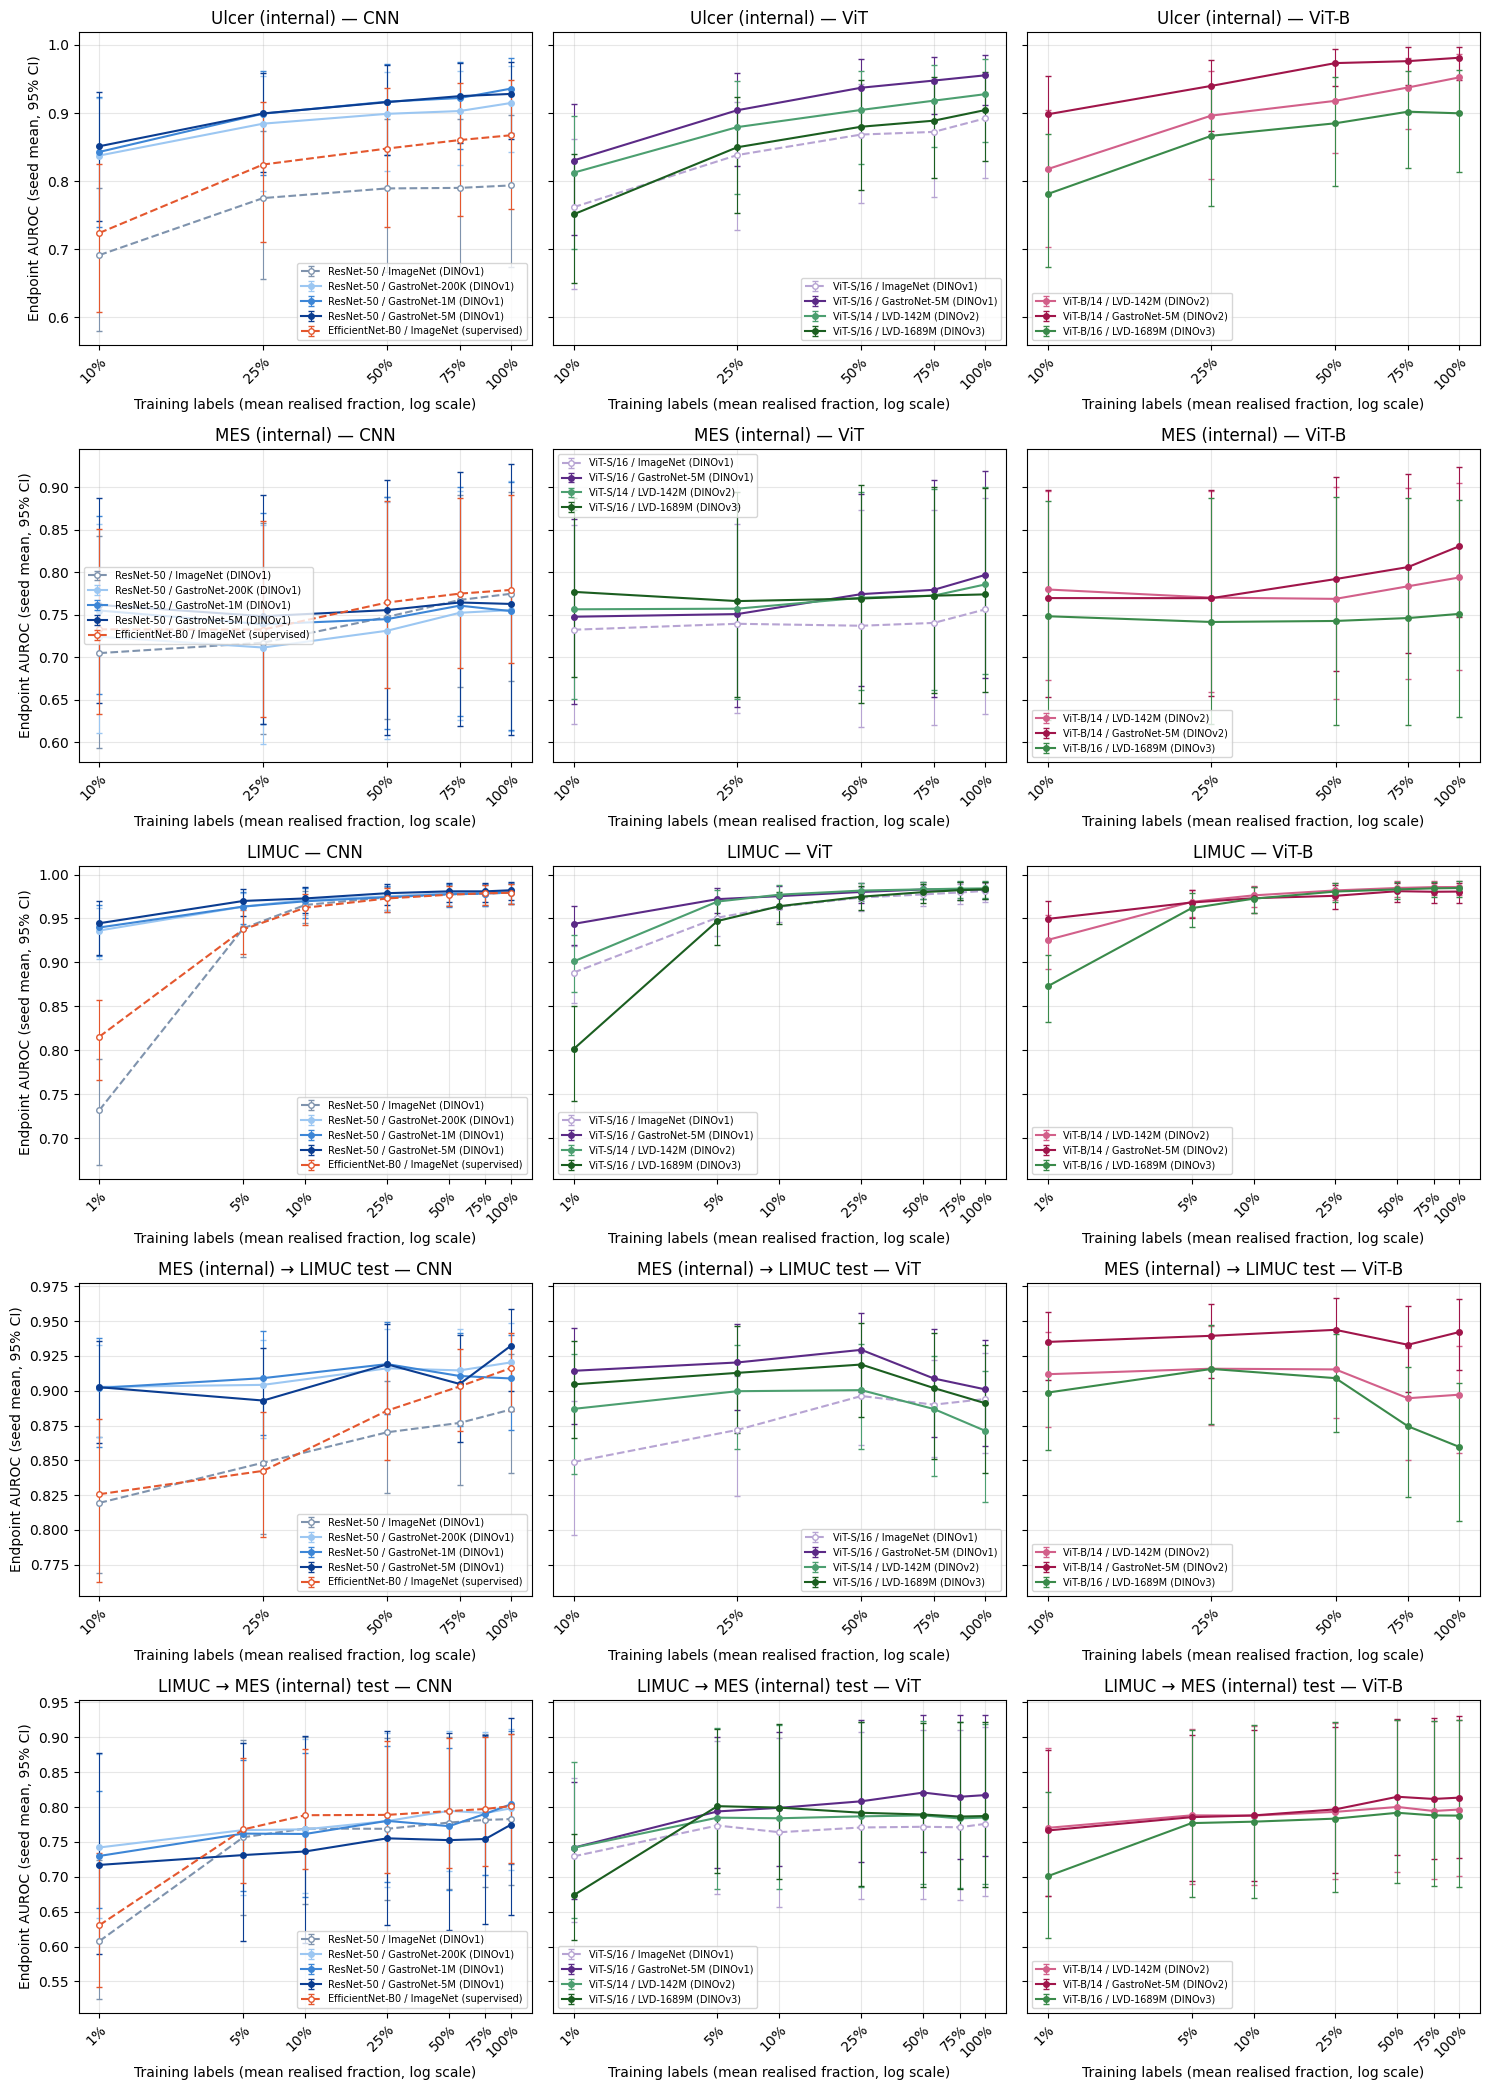

In [31]:
q = [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)]
# One row per dataset, one column per family (CNN | ViT | ViT-B): a ViT-B dataset fills the ViT-B column of its row
rows = list(dict.fromkeys(t.removesuffix("_vitb") for t in BOOT))
families = [f for f in catalog.FAMILY_ORDER if any(catalog.model_family(m) == f for t in BOOT for m in MODELS[t])]
fig, axes = plt.subplots(len(rows), len(families), figsize=(5 * len(families), 4.2 * len(rows)), squeeze=False,
                         sharey="row")
for row, base in zip(axes, rows, strict=True):
    sources = [t for t in (base, f"{base}_vitb") if t in BOOT]
    visible = []
    for ax, family in zip(row, families, strict=True):
        members = [(t, m) for t in sources for m in MODELS[t] if catalog.model_family(m) == family]
        if not members:
            ax.set_visible(False)
            continue
        visible.append(ax)
        for t, m in members:
            bs = BOOT[t]
            x = [100 * np.mean(list(REALISED[t][p].values())) for p in PCTS[t]]
            runs = [f"{m}_{p}pct" for p in PCTS[t]]
            y = np.array([bs.run_mean(r) for r in runs])
            lo, hi = np.percentile([bs.boot_mean(r)[bs.valid] for r in runs], q, axis=1)
            imagenet = "ImageNet" in catalog.model_label(m)
            ax.errorbar(x, y, yerr=[np.clip(y - lo, 0, None), np.clip(hi - y, 0, None)],
                        color=catalog.COLORS[m], linestyle="--" if imagenet else "-", marker="o", markersize=4,
                        markerfacecolor="white" if imagenet else catalog.COLORS[m], capsize=2, elinewidth=0.8,
                        label=catalog.model_label(m))
        ax.set_xscale("log")
        ax.set_xticks(x, [f"{v:.3g}%" for v in x], rotation=45, ha="right", rotation_mode="anchor")
        ax.minorticks_off()
        ax.set(title=f"{NAME[base]} — {family}", xlabel="Training labels (mean realised fraction, log scale)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc="best")
    visible[0].tick_params(labelleft=True)  # y ticks even when the CNN panel is hidden
    visible[0].set_ylabel("Endpoint AUROC (seed mean, 95% CI)")
fig.tight_layout()
plt.show()

## 3. Contrasts

ΔAULC (primary outcome for the `matched` family) and ΔAUROC at full labels (secondary); `p_sup_adj` and the verdict
(α = 0.05) are Holm-adjusted within the family.

ΔAULC [95% CI], Holm p  \
dataset                family       challenger       baseline                                              
ulcer                  matched      resnet50_5M      resnet50_imagenet  +0.134 [+0.072, +0.205], p=0.000   
                                    vits16_gastronet vits16_imagenet    +0.068 [+0.026, +0.119], p=0.002   
                       corpus_size  resnet50_1M      resnet50_200K      +0.015 [-0.001, +0.035], p=0.187   
                                    resnet50_5M      resnet50_1M        +0.002 [-0.019, +0.021], p=0.789   
                                                     resnet50_200K      +0.016 [-0.001, +0.039], p=0.187   
                       generic      vits14_dinov2    vits16_gastronet   -0.026 [-0.064, +0.004], p=0.190   
                                                     vits16_imagenet    +0.042 [+0.015, +0.077], p=0.008   
                                    vits16_dinov3    vits16_gastronet   -0.061 [-0.101, -0.027], p=0.001   
                                                     vits16_imagenet    +0.008 [-0.017, +0.038], p=0.488   
mes                    matched      resnet50_5M      resnet50_imagenet  +0.023 [-0.024, +0.068], p=0.300   
                                    vits16_gastronet vits16_imagenet    +0.024 [-0.000, +0.048], p=0.104   
                       corpus_size  resnet50_1M      resnet50_200K      +0.020 [-0.004, +0.046], p=0.196   
                                    resnet50_5M      resnet50_1M        +0.008 [-0.017, +0.031], p=0.398   
                                                     resnet50_200K      +0.028 [-0.002, +0.064], p=0.196   
                       generic      vits14_dinov2    vits16_gastronet   +0.001 [-0.022, +0.027], p=1.000   
                                                     vits16_imagenet    +0.026 [+0.009, +0.042], p=0.015   
                                    vits16_dinov3    vits16_gastronet   +0.007 [-0.018, +0.035], p=1.000   
                                                     vits16_imagenet    +0.032 [+0.010, +0.053], p=0.025   
limuc                  matched      resnet50_5M      resnet50_imagenet  +0.048 [+0.036, +0.062], p=0.000   
                                    vits16_gastronet vits16_imagenet    +0.019 [+0.012, +0.028], p=0.000   
                       corpus_size  resnet50_1M      resnet50_200K      -0.000 [-0.005, +0.005], p=0.976   
                                    resnet50_5M      resnet50_1M        +0.004 [-0.002, +0.011], p=0.290   
                                                     resnet50_200K      +0.004 [-0.000, +0.009], p=0.155   
                       generic      vits14_dinov2    vits16_gastronet   -0.007 [-0.015, -0.001], p=0.025   
                                                     vits16_imagenet    +0.012 [+0.006, +0.018], p=0.001   
                                    vits16_dinov3    vits16_gastronet   -0.034 [-0.049, -0.022], p=0.001   
                                                     vits16_imagenet    -0.015 [-0.026, -0.006], p=0.001   
internal_to_limuc      matched      resnet50_5M      resnet50_imagenet  +0.051 [+0.031, +0.072], p=0.000   
                                    vits16_gastronet vits16_imagenet    +0.041 [+0.025, +0.059], p=0.000   
                       corpus_size  resnet50_1M      resnet50_200K      +0.001 [-0.016, +0.018], p=1.000   
                                    resnet50_5M      resnet50_1M        -0.005 [-0.019, +0.008], p=1.000   
                                                     resnet50_200K      -0.004 [-0.018, +0.010], p=1.000   
                       generic      vits14_dinov2    vits16_gastronet   -0.025 [-0.046, -0.005], p=0.044   
                                                     vits16_imagenet    +0.016 [-0.001, +0.034], p=0.137   
                                    vits16_dinov3    vits16_gastronet   -0.009 [-0.028, +0.010], p=0.339   
                                                     vits16_imagenet    +0.032 [+0.016

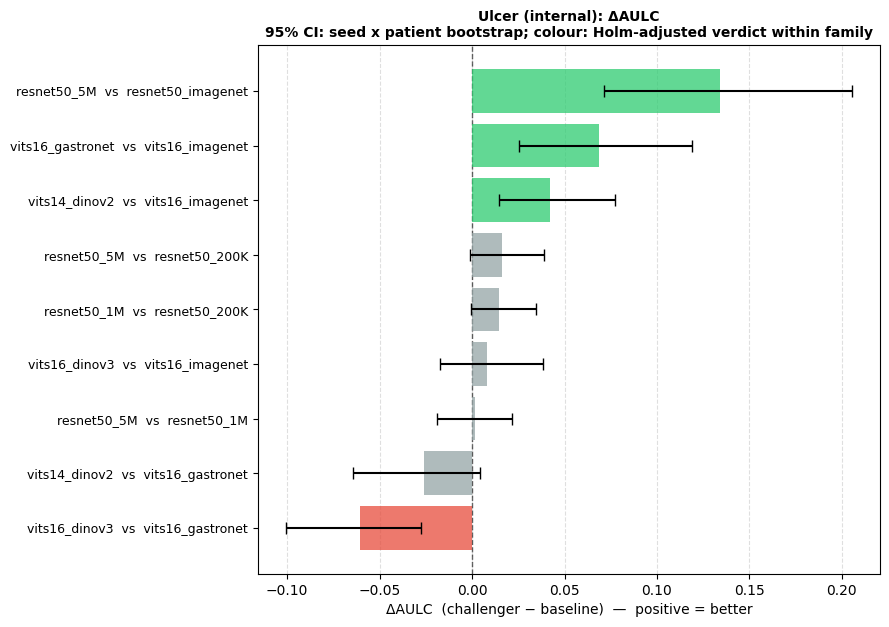

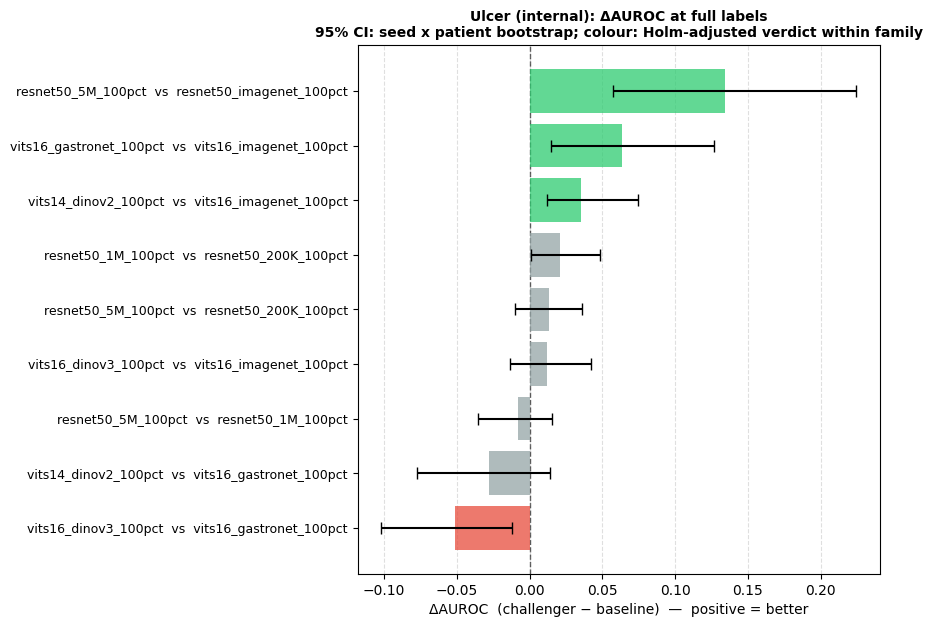

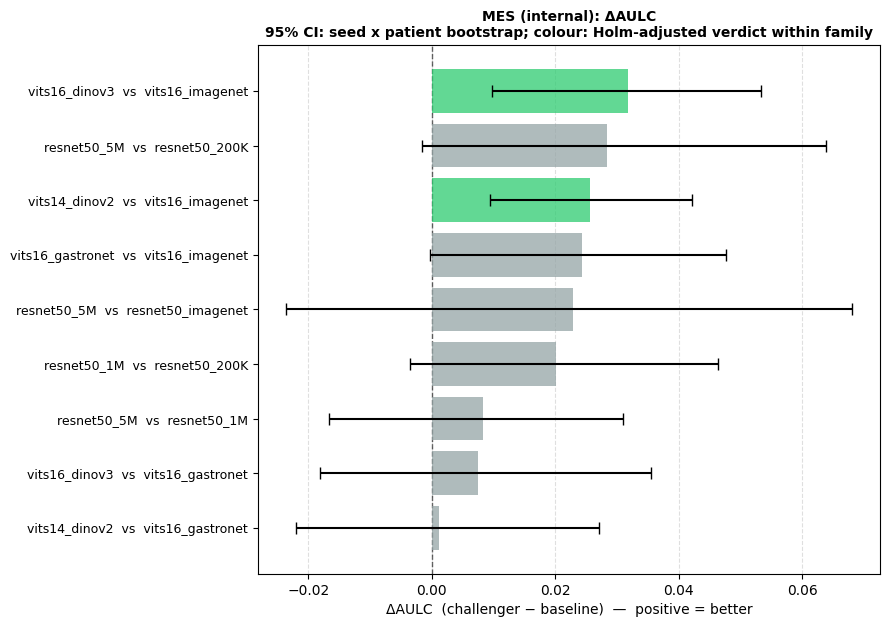

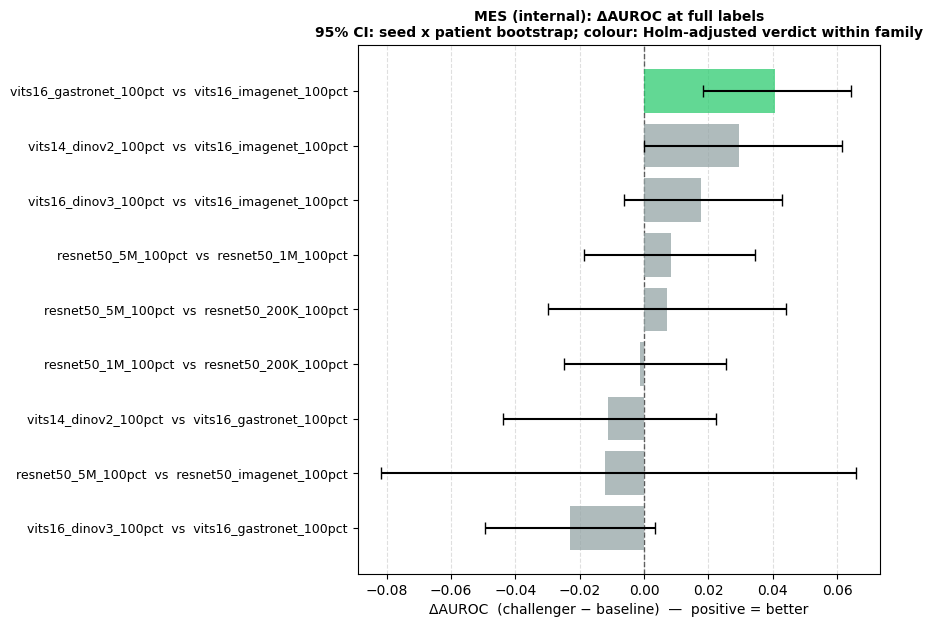

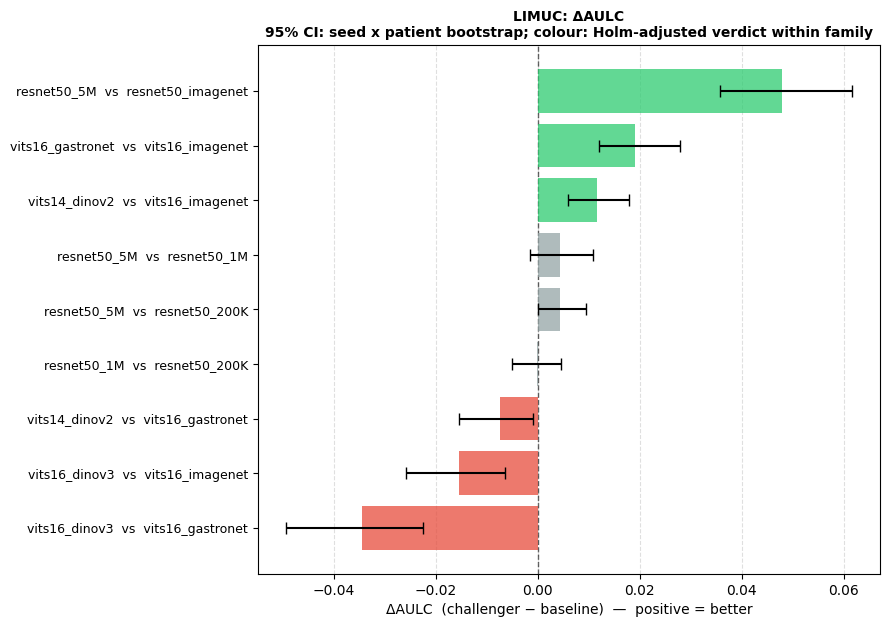

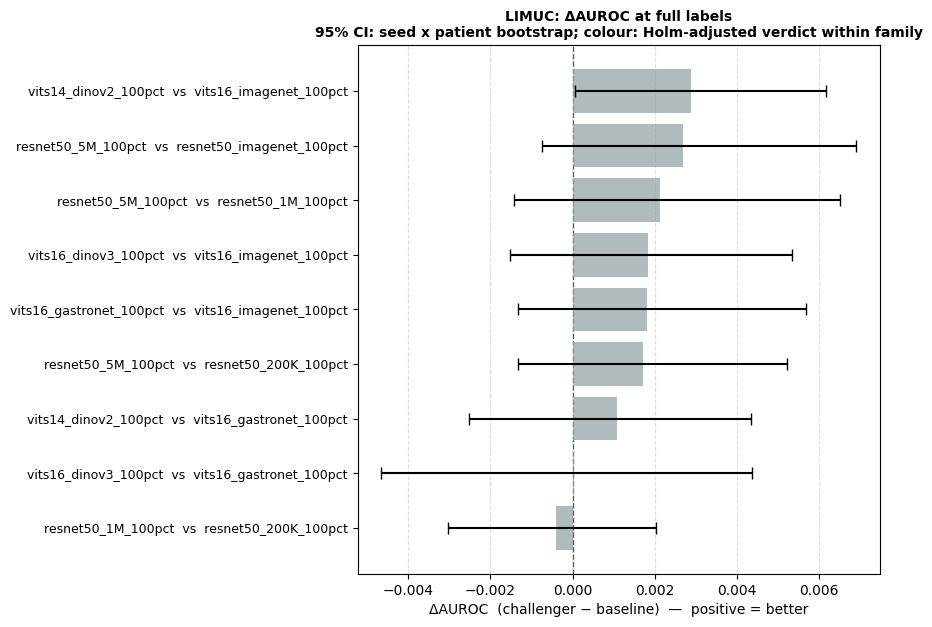

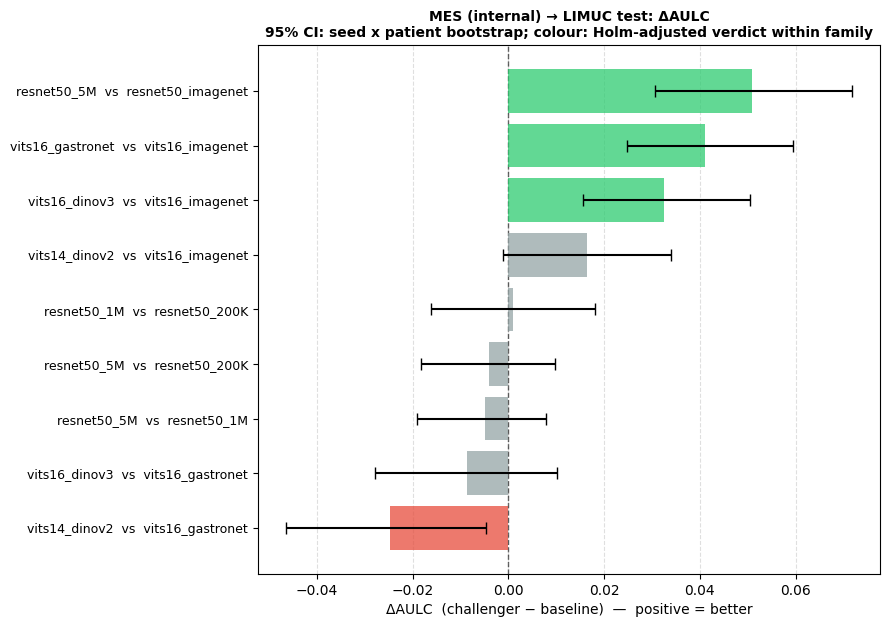

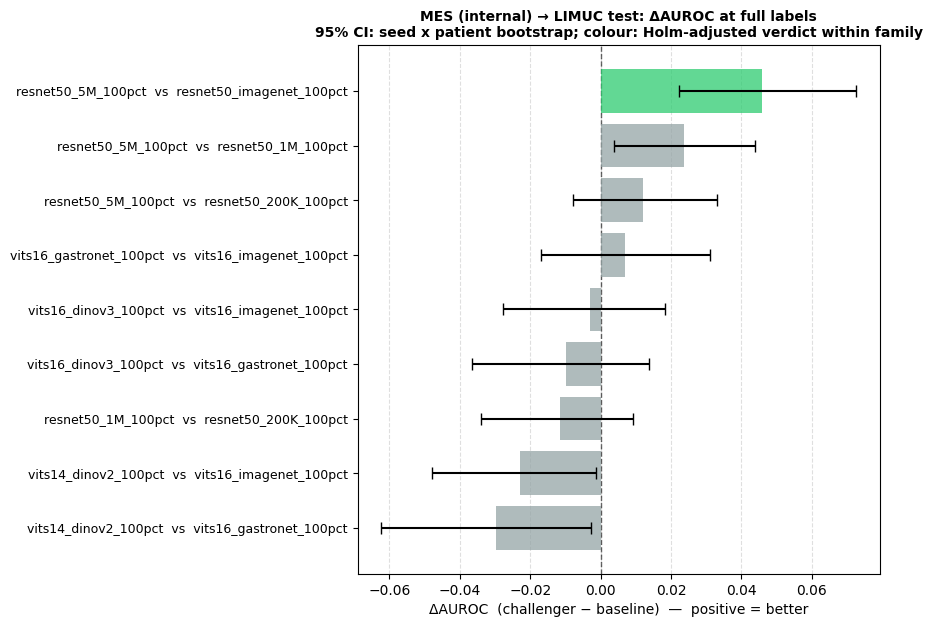

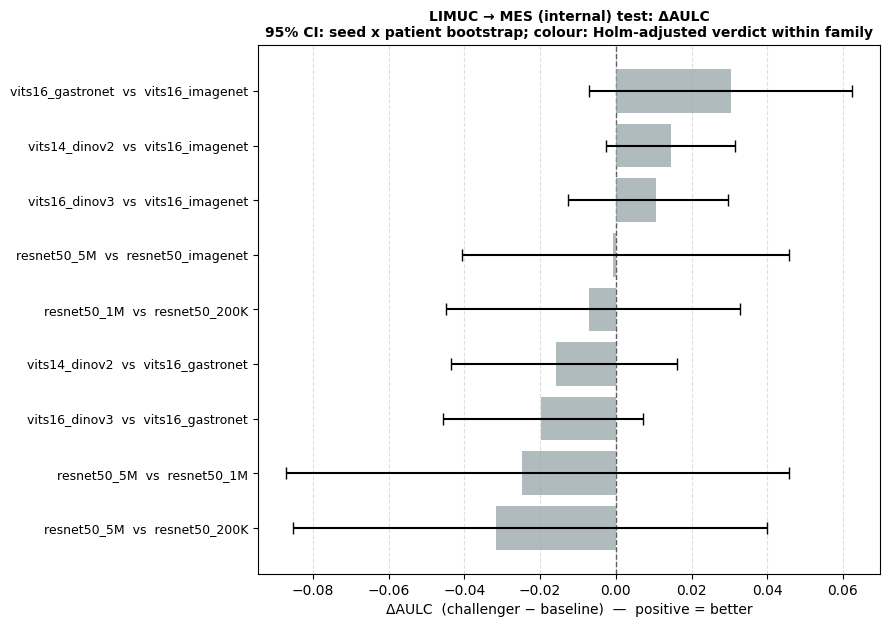

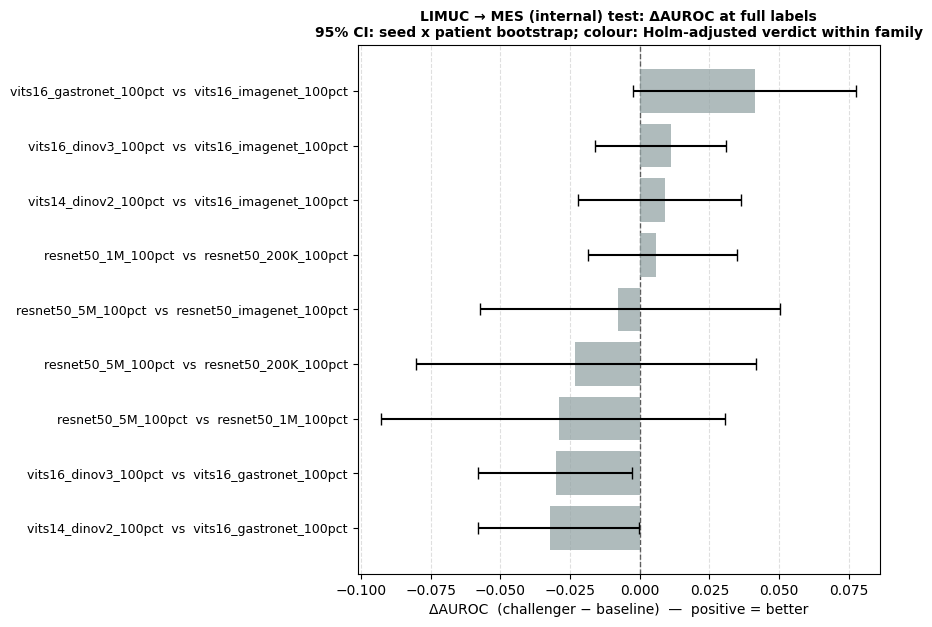

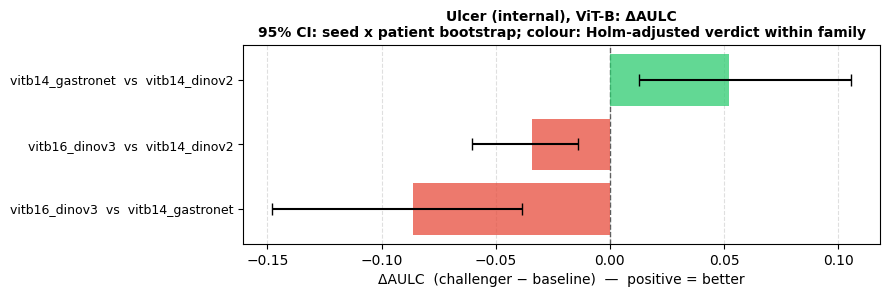

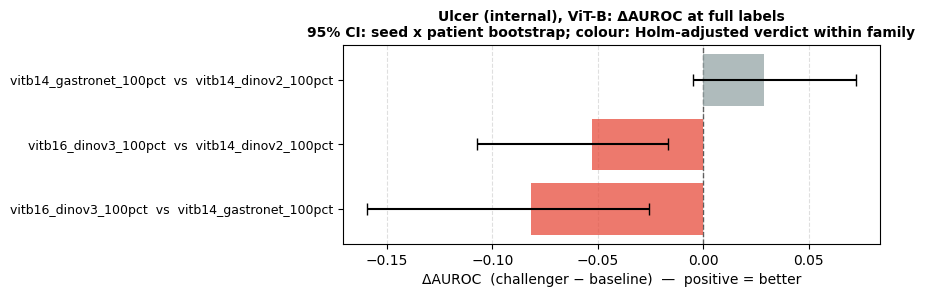

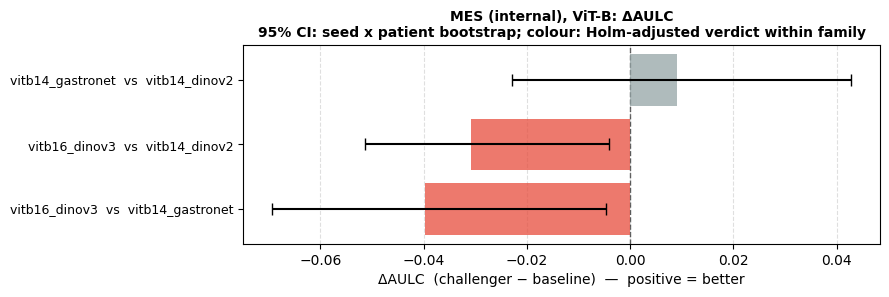

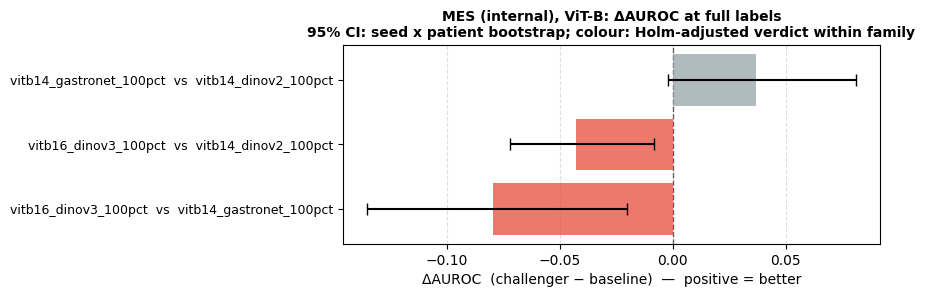

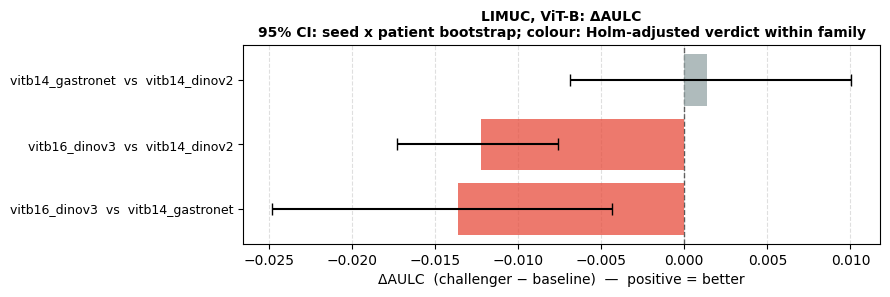

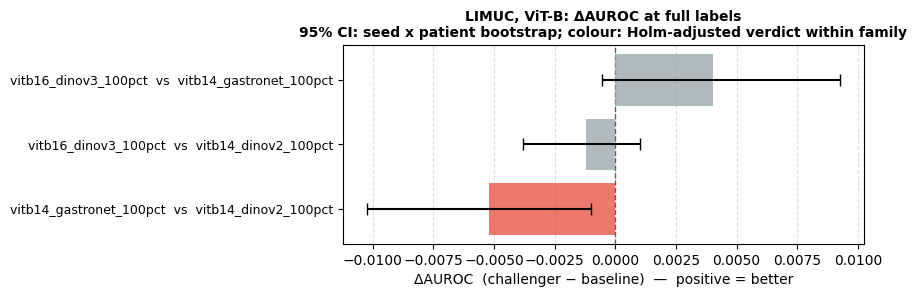

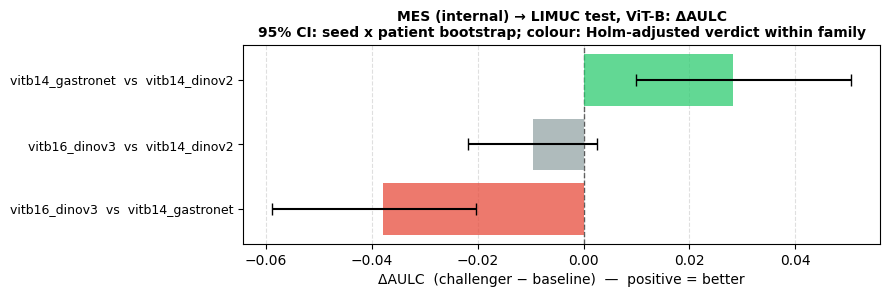

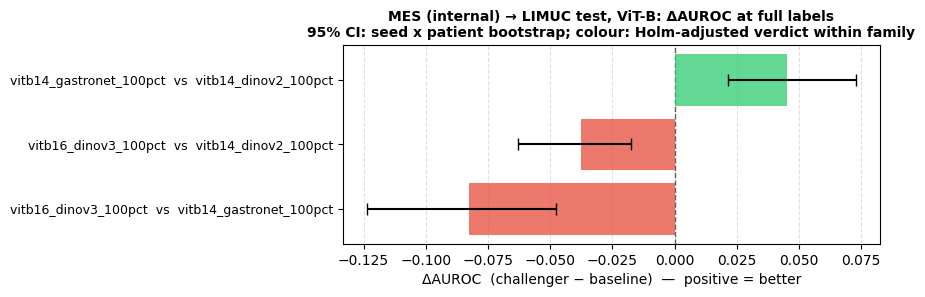

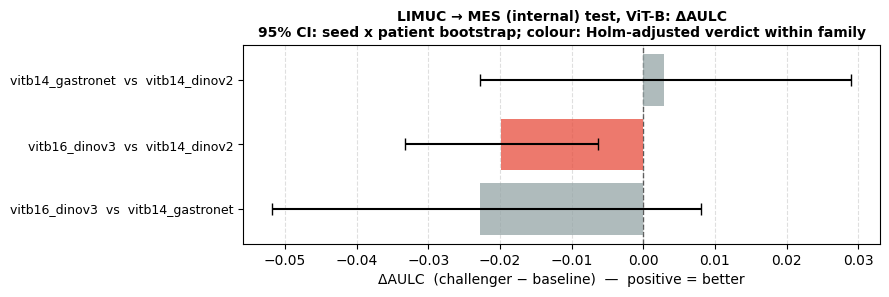

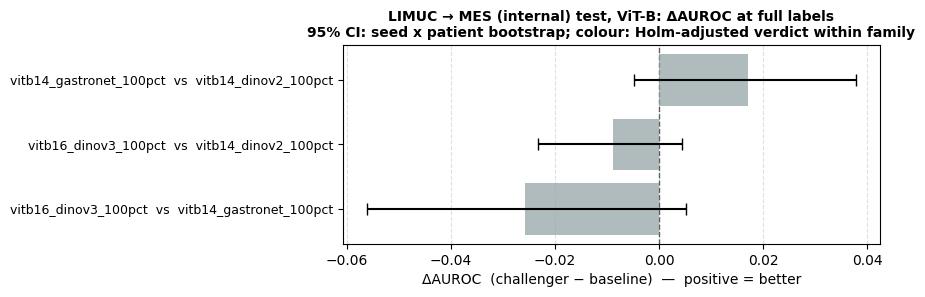

In [32]:
def family_pairs(task: str) -> dict[str, list[tuple[str, str]]]:
    """Pairs of each family whose two models have results (empty families dropped)."""
    pairs = {f: [p for p in ps if set(p) <= set(MODELS[task])] for f, ps in FAMILIES.items()}
    return {f: ps for f, ps in pairs.items() if ps}


def tag(table: pd.DataFrame, task: str, family: str) -> pd.DataFrame:
    """Contrast table with its dataset, family and bootstrap context as columns."""
    a = table.attrs
    table.insert(0, "family", family)
    table.insert(0, "dataset", task)
    return table.assign(endpoint=a["endpoint"], n_patients=a["n_clips"], n_seeds=a["n_seeds"],
                        n_boot_valid=a["n_boot"])


def ci_text(t: pd.DataFrame, delta: str) -> pd.Series:
    return t.apply(lambda r: f"{r[delta]:+.3f} [{r.ci_lo:+.3f}, {r.ci_hi:+.3f}], p={r.p_sup_adj:.3f}",
                   axis=1)


def forest(table: pd.DataFrame, title: str) -> None:
    """plot_comparison_forest, titled for the patient-level bootstrap and the families."""
    table.attrs = {"tested": True}
    ax = plot_comparison_forest(table).axes[0]
    ax.get_legend().remove()
    ax.set_title(f"{title}\n95% CI: seed x patient bootstrap; colour: Holm-adjusted verdict within family",
                 fontsize=10, fontweight="bold")
    plt.show()


auroc_tables, aulc_tables = [], []
for task, bs in BOOT.items():
    full = PCTS[task][-1]
    for family, pairs in family_pairs(task).items():
        runs = [(f"{c}_{full}pct", f"{b}_{full}pct") for c, b in pairs]
        auroc_tables.append(tag(auroc_contrasts(bs, runs, alpha=ALPHA), task, family))
        aulc_tables.append(tag(aulc_contrasts(bs, pairs, REALISED[task], alpha=ALPHA), task, family))
CONTRASTS = pd.concat(auroc_tables, ignore_index=True)
AULC = pd.concat(aulc_tables, ignore_index=True)
assert len(AULC) == len(CONTRASTS)

display(AULC[["dataset", "family", "challenger", "baseline"]].assign(**{
    "ΔAULC [95% CI], Holm p": ci_text(AULC, "ΔAULC"),
    "ΔAUROC at full labels [95% CI], Holm p": ci_text(CONTRASTS, "ΔAUROC"),
}).set_index(["dataset", "family", "challenger", "baseline"]))
for task in BOOT:
    forest(AULC[AULC["dataset"] == task].copy(), f"{NAME[task]}: ΔAULC")
    forest(CONTRASTS[CONTRASTS["dataset"] == task].copy(), f"{NAME[task]}: ΔAUROC at full labels")

### 3b. Seed consistency (Wilcoxon)

Exact signed-rank test of the per-seed Δ, Holm within each family; `seeds` = seeds favouring the challenger.
With n seeds p ≥ 2/2ⁿ, reached when every seed agrees (0.002 for 10). The test patients are fixed: a small p
means the Δ is consistent across seeds on this test set, not that it holds for new patients (the bootstrap of
Section 3 resamples both). Figure: one dot per seed, the median (tick) and the bootstrap 95 % CI (grey bar);
dots all on one side of 0 while the grey bar crosses it = consistent across seeds, not shown on patients.

seeds  \
dataset                family       measure challenger              baseline                          
ulcer                  matched      ΔAULC   resnet50_5M             resnet50_imagenet         10/10   
                                            vits16_gastronet        vits16_imagenet           10/10   
                                    ΔAUROC  resnet50_5M_100pct      resnet50_imagenet_100pct  10/10   
                                            vits16_gastronet_100pct vits16_imagenet_100pct    10/10   
                       corpus_size  ΔAULC   resnet50_1M             resnet50_200K              9/10   
                                            resnet50_5M             resnet50_1M                7/10   
                                                                    resnet50_200K              9/10   
                                    ΔAUROC  resnet50_1M_100pct      resnet50_200K_100pct      10/10   
                                            resnet50_5M_100pct      resnet50_1M_100pct         2/10   
                                                                    resnet50_200K_100pct      10/10   
                       generic      ΔAULC   vits14_dinov2           vits16_gastronet           2/10   
                                                                    vits16_imagenet           10/10   
                                            vits16_dinov3           vits16_gastronet           0/10   
                                                                    vits16_imagenet            6/10   
                                    ΔAUROC  vits14_dinov2_100pct    vits16_gastronet_100pct    0/10   
                                                                    vits16_imagenet_100pct    10/10   
                                            vits16_dinov3_100pct    vits16_gastronet_100pct    0/10   
                                                                    vits16_imagenet_100pct     5/10   
mes                    matched      ΔAULC   resnet50_5M             resnet50_imagenet          8/10   
                                            vits16_gastronet        vits16_imagenet            8/10   
                                    ΔAUROC  resnet50_5M_100pct      resnet50_imagenet_100pct   3/10   
                                            vits16_gastronet_100pct vits16_imagenet_100pct    10/10   
                       corpus_size  ΔAULC   resnet50_1M             resnet50_200K              8/10   
                                            resnet50_5M             resnet50_1M                7/10   
                                                                    resnet50_200K              9/10   
                                    ΔAUROC  resnet50_1M_100pct      resnet50_200K_100pct       4/10   
                                            resnet50_5M_100pct      resnet50_1M_100pct         5/10   
                                                                    resnet50_200K_100pct       5/10   
                       generic      ΔAULC   vits14_dinov2           vits16_gastronet           5/10   
                                                                    vits16_imagenet           10/10   
                                            vits16_dinov3           vits16_gastronet           8/10   
                                                                    vits16_imagenet            9/10   
                                    ΔAUROC  vits14_dinov2_100pct    vits16_gastronet_100pct    3/10   
                                                                    vits16_imagenet_100pct    10/10   
                                            vits16_dinov3_100pct    vits16_gastronet_100pct    2/10   
                                                                    vits16_imagenet_100pct    10/10   
limuc                  matched      ΔAULC   resnet50_5M             resnet50_imagenet         10/10   
                                            vits16_gastronet        vits16_im

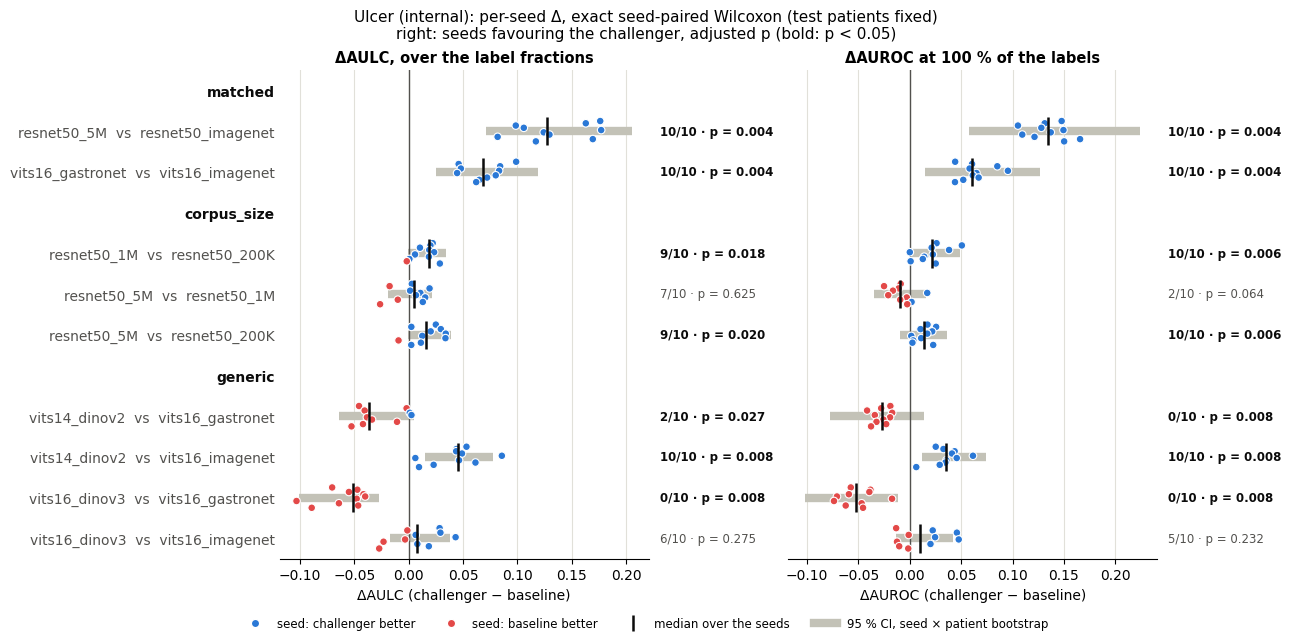

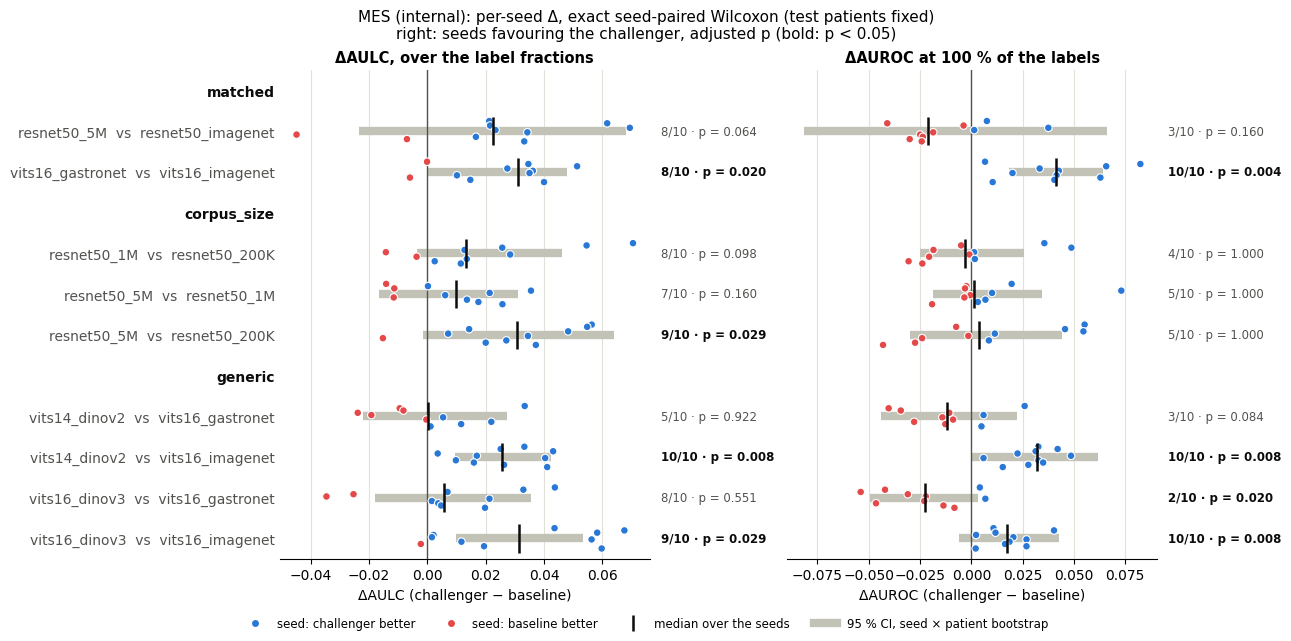

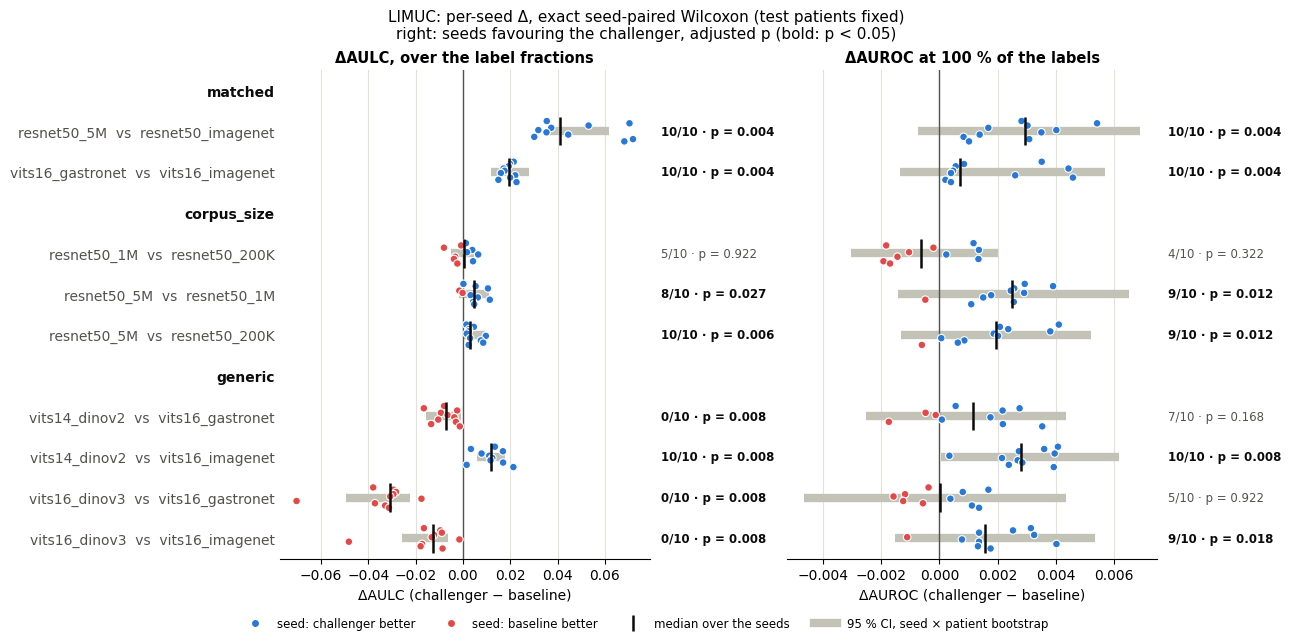

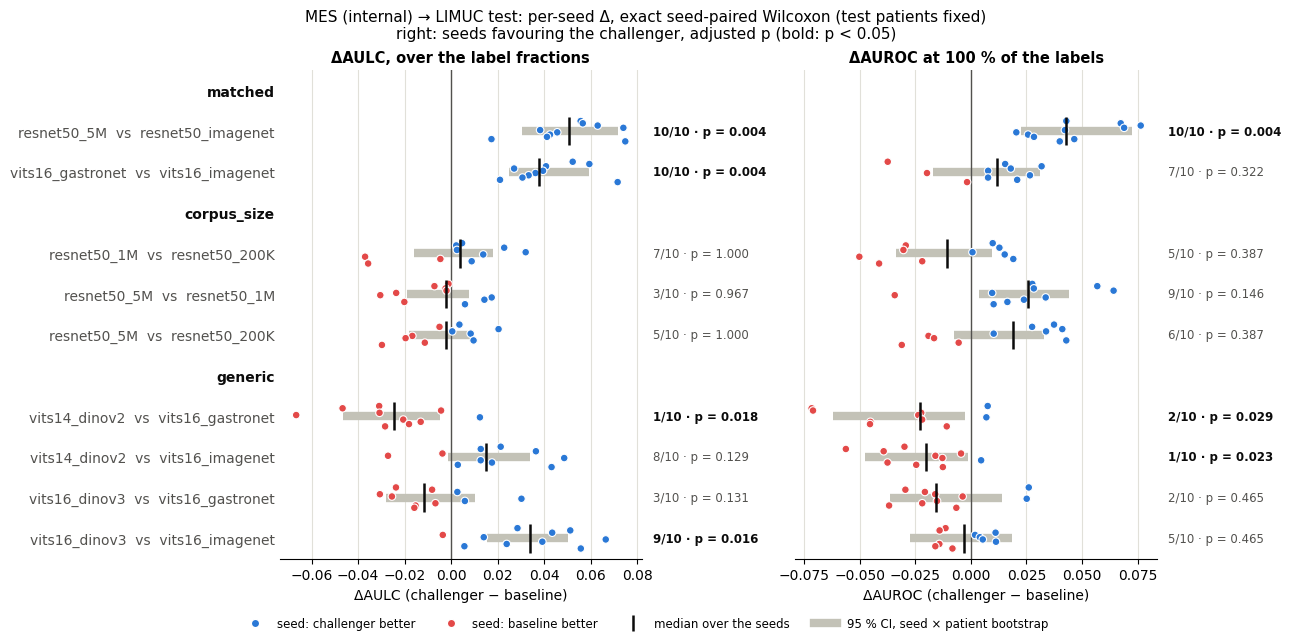

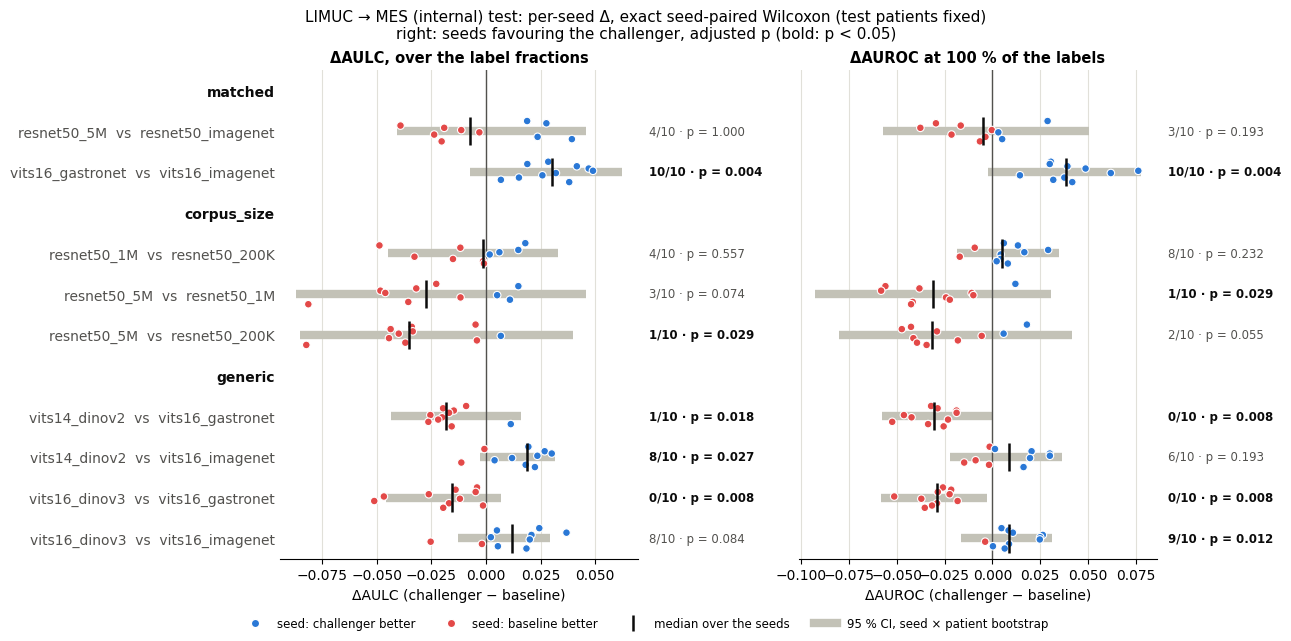

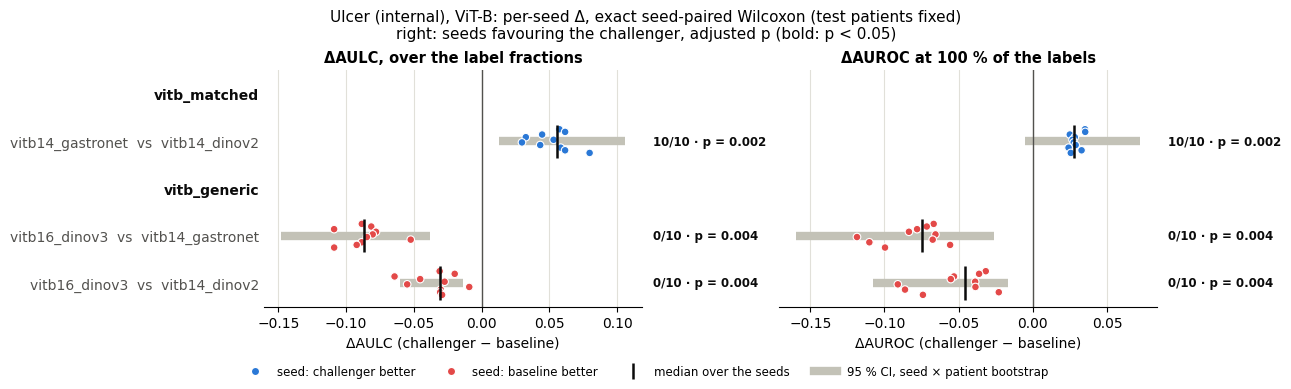

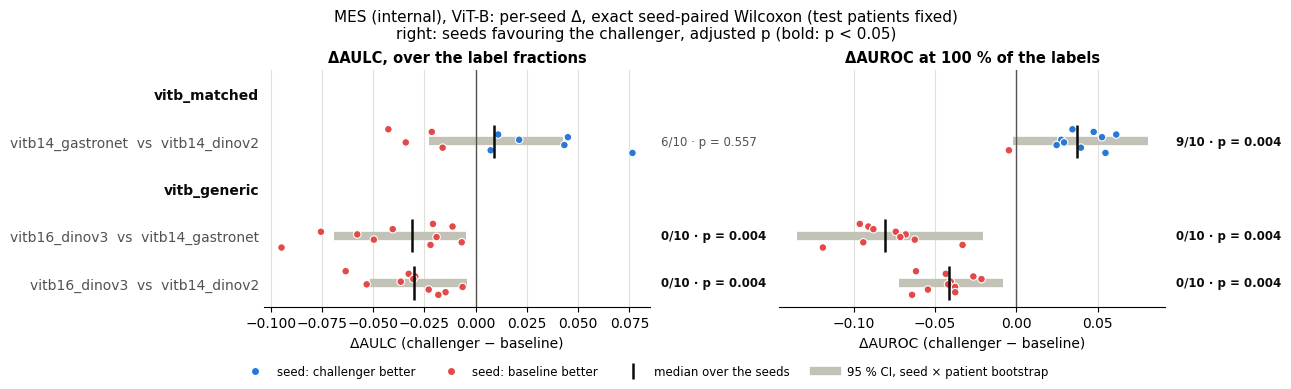

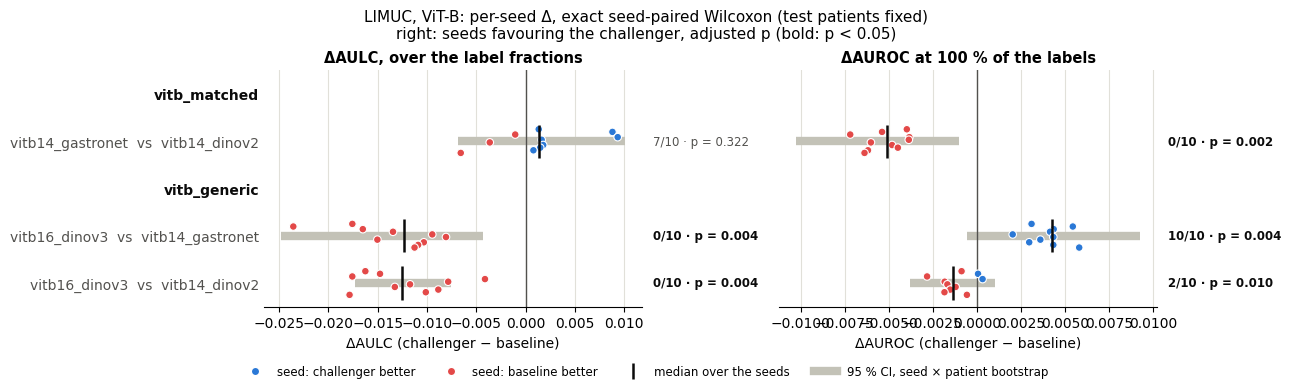

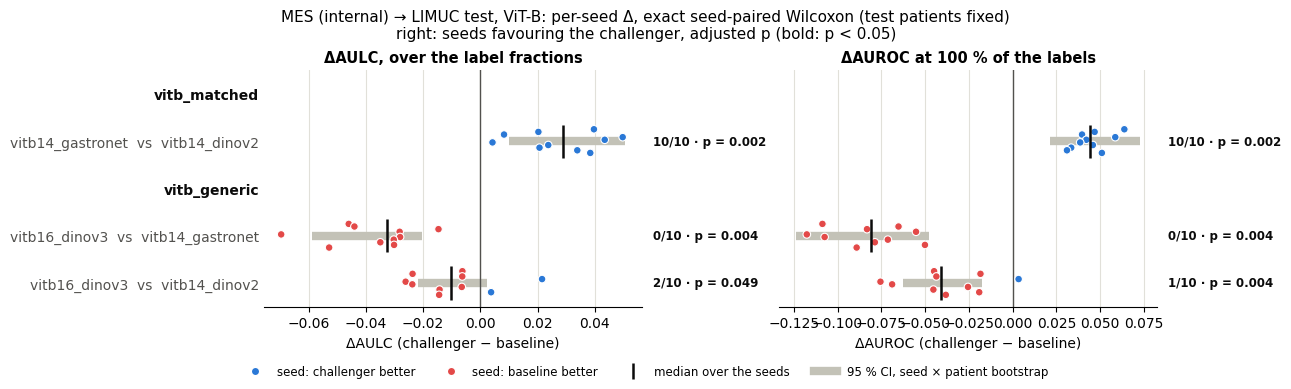

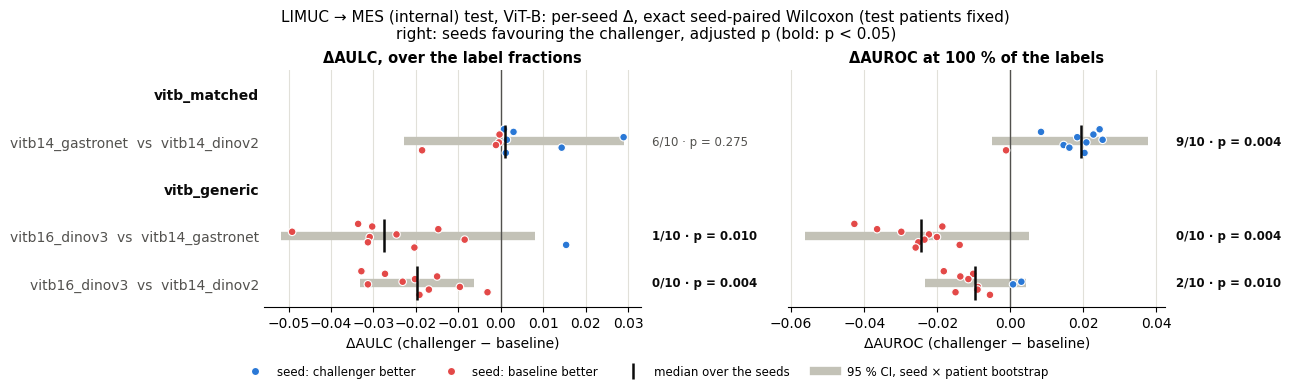

In [33]:
wilcoxon_tables, seed_tables = [], []
for task, bs in BOOT.items():
    full = PCTS[task][-1]
    for family, pairs in family_pairs(task).items():
        runs = [(f"{c}_{full}pct", f"{b}_{full}pct") for c, b in pairs]
        for args in ((pairs, REALISED[task]), (runs,)):
            wilcoxon_tables.append(seed_wilcoxon(bs, *args).assign(dataset=task, family=family))
            seed_tables.append(seed_deltas(bs, *args).assign(dataset=task, family=family))
WILCOXON = pd.concat(wilcoxon_tables, ignore_index=True)
SEED_DELTAS = pd.concat(seed_tables, ignore_index=True)
display(WILCOXON.assign(seeds=WILCOXON["n_pos"].astype(str) + "/" + WILCOXON["n_seeds"].astype(str))
        .set_index(["dataset", "family", "measure", "challenger", "baseline"])
        [["seeds", "median Δ", "p_exact", "p_adj"]].round(4))
for task in BOOT:
    plot_seed_deltas(SEED_DELTAS[SEED_DELTAS["dataset"] == task], WILCOXON[WILCOXON["dataset"] == task],
                     [AULC[AULC["dataset"] == task], CONTRASTS[CONTRASTS["dataset"] == task]], alpha=ALPHA,
                     title=f"{NAME[task]}: per-seed Δ, exact seed-paired Wilcoxon (test patients fixed)")
    plt.show()

## 4. Label efficiency

Fraction of labels each model needs to reach the full-label AUROC of the ImageNet model of its architecture
(ViT-B: the LVD-142M DINOv2 model).
Estimator: for each seed, linear interpolation of logit AUROC between its own realised fractions (log2 scale), then
the median over the seeds; 95 % seed × patient bootstrap interval; no extrapolation ('<min' / '>max').
`interval_spans_range` flags an interval covering the whole tested range (uninformative). The fitted logit-linear
curves of the figures are descriptive: neither the estimate nor the AULC depends on them. ΔAULC is tested in
Section 3.

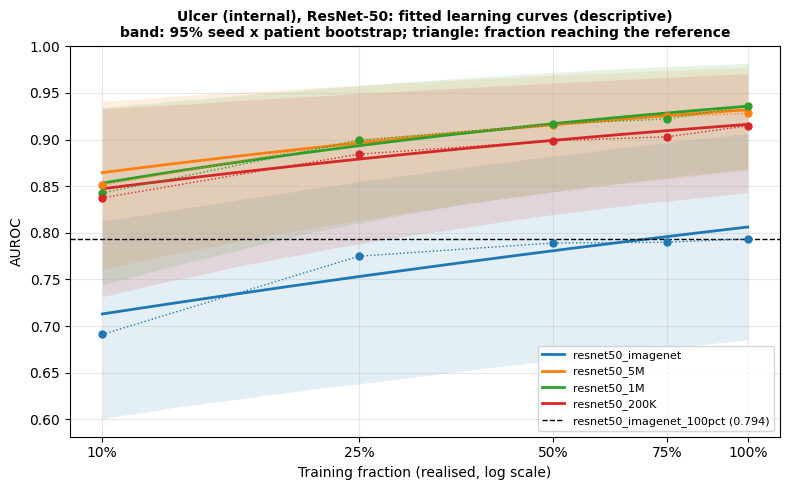

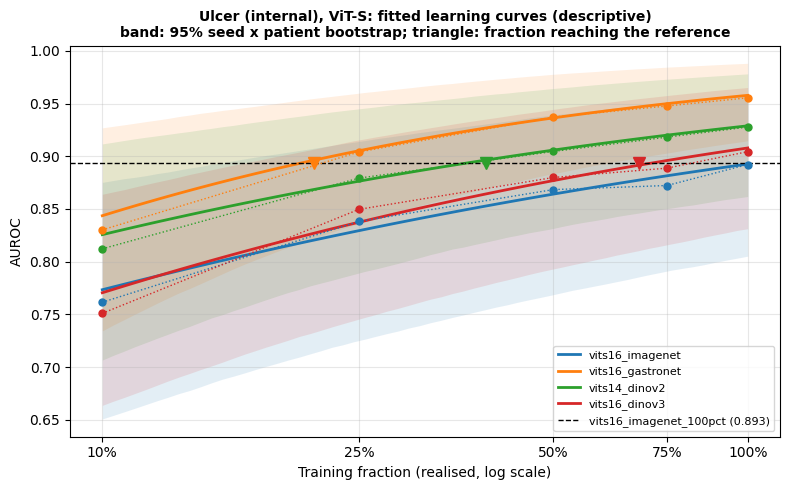

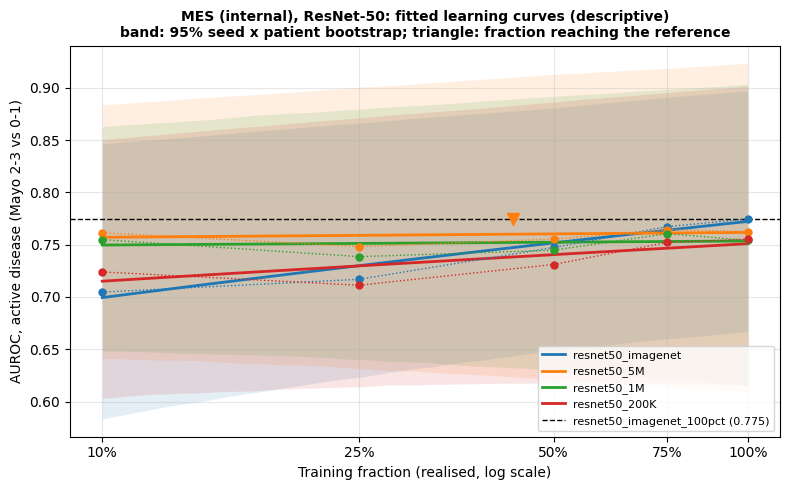

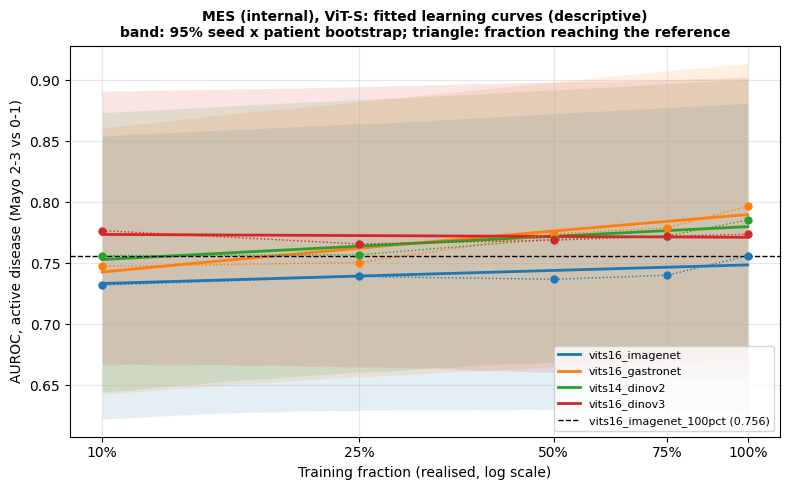

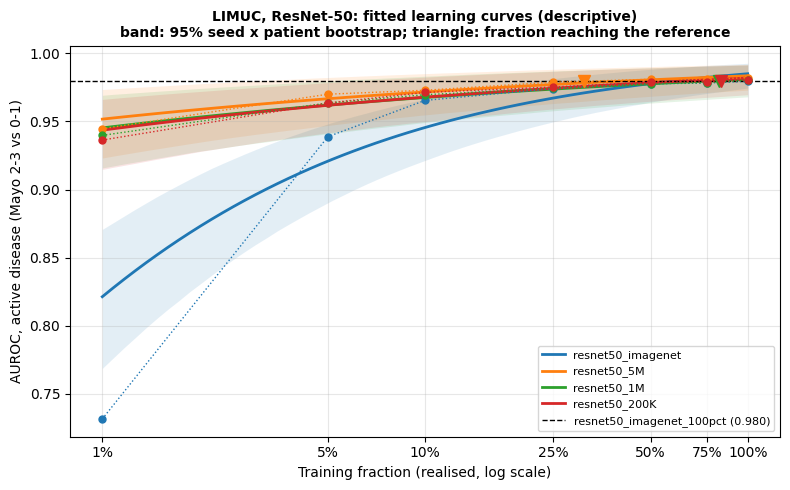

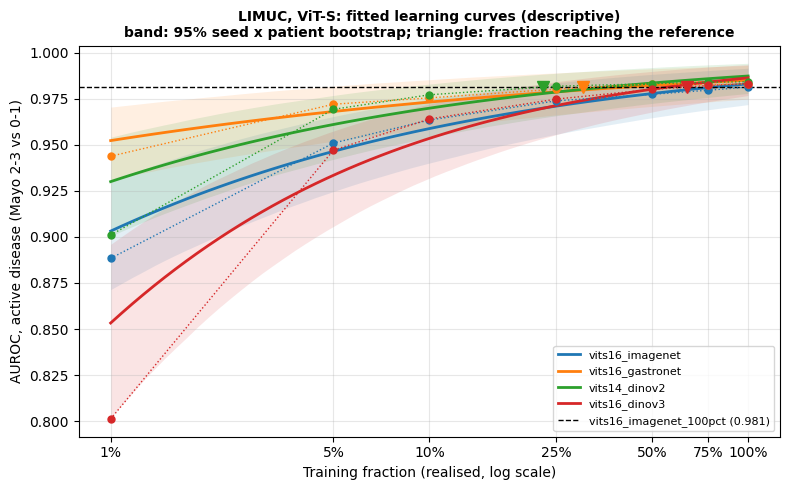

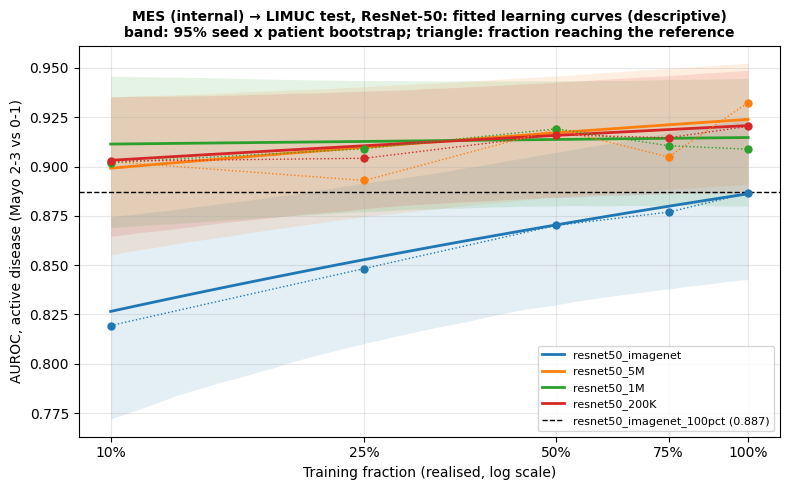

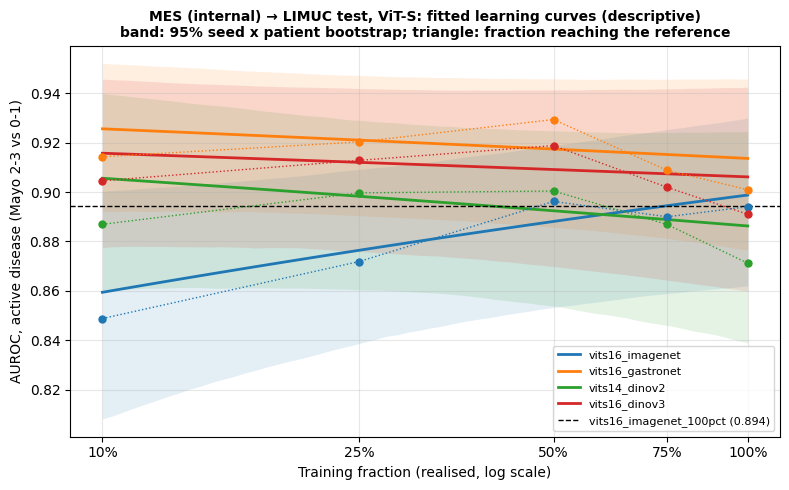

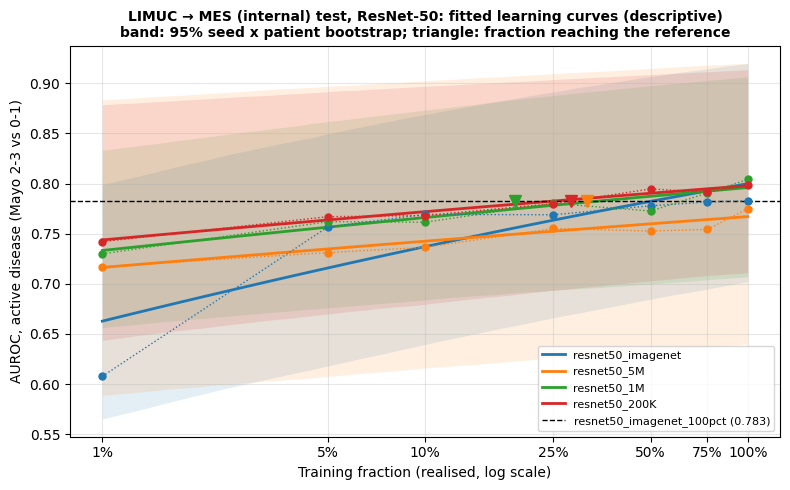

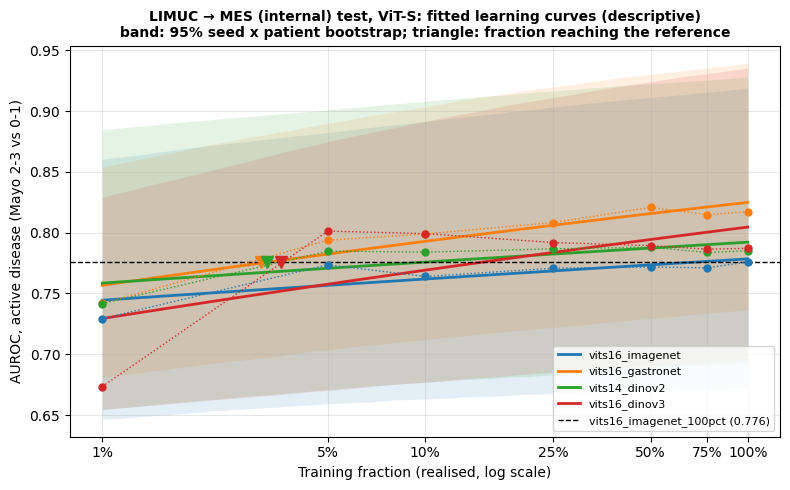

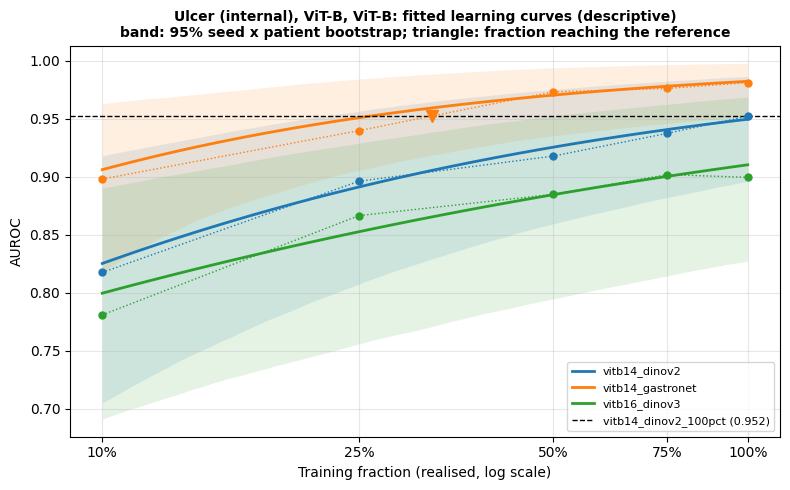

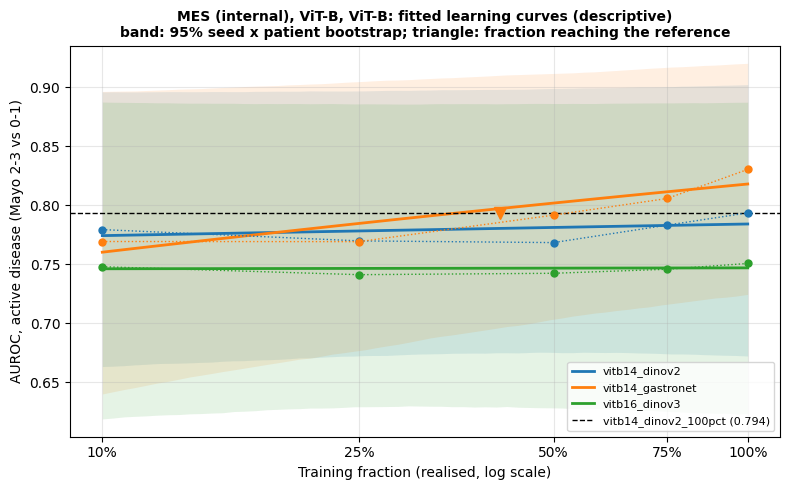

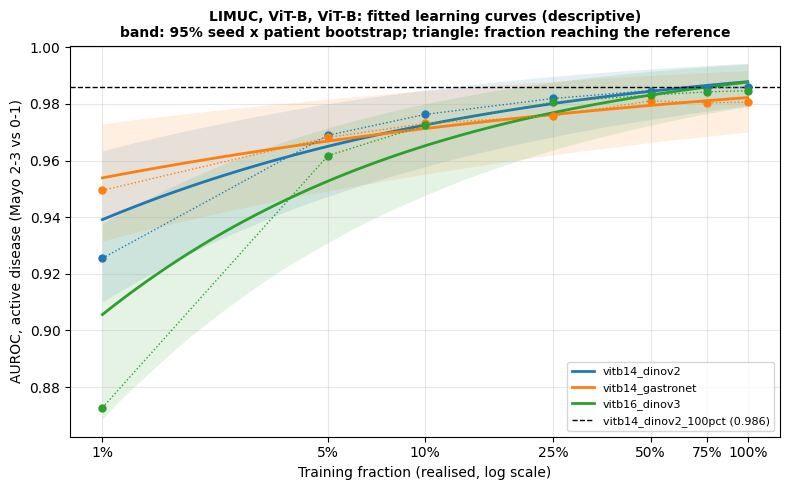

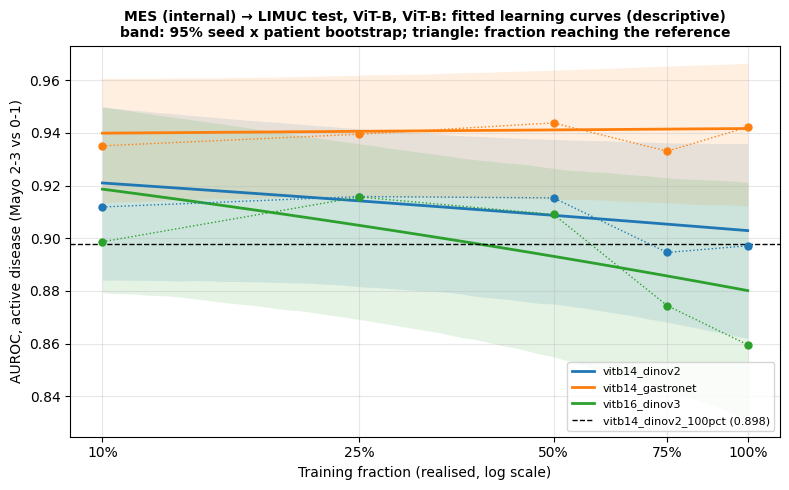

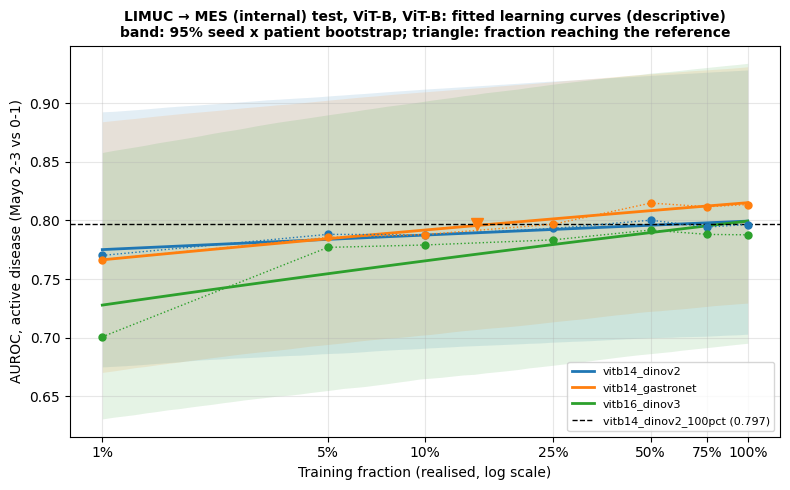

reference  \
dataset                architecture model                                         
ulcer                  ResNet-50    resnet50_imagenet  resnet50_imagenet_100pct   
                                    resnet50_5M        resnet50_imagenet_100pct   
                                    resnet50_1M        resnet50_imagenet_100pct   
                                    resnet50_200K      resnet50_imagenet_100pct   
                       ViT-S        vits16_imagenet      vits16_imagenet_100pct   
                                    vits16_gastronet     vits16_imagenet_100pct   
                                    vits14_dinov2        vits16_imagenet_100pct   
                                    vits16_dinov3        vits16_imagenet_100pct   
mes                    ResNet-50    resnet50_imagenet  resnet50_imagenet_100pct   
                                    resnet50_5M        resnet50_imagenet_100pct   
                                    resnet50_1M        resnet50_imagenet_100pct   
                                    resnet50_200K      resnet50_imagenet_100pct   
                       ViT-S        vits16_imagenet      vits16_imagenet_100pct   
                                    vits16_gastronet     vits16_imagenet_100pct   
                                    vits14_dinov2        vits16_imagenet_100pct   
                                    vits16_dinov3        vits16_imagenet_100pct   
limuc                  ResNet-50    resnet50_imagenet  resnet50_imagenet_100pct   
                                    resnet50_5M        resnet50_imagenet_100pct   
                                    resnet50_1M        resnet50_imagenet_100pct   
                                    resnet50_200K      resnet50_imagenet_100pct   
                       ViT-S        vits16_imagenet      vits16_imagenet_100pct   
                                    vits16_gastronet     vits16_imagenet_100pct   
                                    vits14_dinov2        vits16_imagenet_100pct   
                                    vits16_dinov3        vits16_imagenet_100pct   
internal_to_limuc      ResNet-50    resnet50_imagenet  resnet50_imagenet_100pct   
                                    resnet50_5M        resnet50_imagenet_100pct   
                                    resnet50_1M        resnet50_imagenet_100pct   
                                    resnet50_200K      resnet50_imagenet_100pct   
                       ViT-S        vits16_imagenet      vits16_imagenet_100pct   
                                    vits16_gastronet     vits16_imagenet_100pct   
                                    vits14_dinov2        vits16_imagenet_100pct   
                                    vits16_dinov3        vits16_imagenet_100pct   
limuc_to_internal      ResNet-50    resnet50_imagenet  resnet50_imagenet_100pct   
                                    resnet50_5M        resnet50_imagenet_100pct   
                                    resnet50_1M        resnet50_imagenet_100pct   
                                    resnet50_200K      resnet50_imagenet_100pct   
                       ViT-S        vits16_imagenet      vits16_imagenet_100pct   
                                    vits16_gastronet     vits16_imagenet_100pct   
                                    vits14_dinov2        vits16_imagenet_100pct   
                                    vits16_dinov3        vits16_imagenet_100pct   
ulcer_vitb             ViT-B        vitb14_dinov2          vitb14_dinov2_100pct   
                                    vitb14_gastronet       vitb14_dinov2_100pct   
                                    vitb16_dinov3          vitb14_dinov2_100pct   
mes_vitb               ViT-B        vitb14_dinov2          vitb14_dinov2_100pct   
                                    vitb14_gastronet       vitb14_dinov2_100pct   
                                    vitb16_dinov3          vitb14_dinov2_100pct   
limuc_vitb             ViT-B        vitb14_dinov2          vitb14_dinov2_100pct   
   

Interval spanning the whole tested range: mes resnet50_5M, mes resnet50_1M, mes resnet50_200K, limuc_to_internal resnet50_5M, limuc_to_internal resnet50_200K, limuc_to_internal vits14_dinov2, ulcer_vitb vitb14_gastronet, mes_vitb vitb16_dinov3, limuc_to_internal_vitb vitb14_gastronet


In [34]:
def spans_range(text: str) -> bool:
    """True for an interval '[<min, >max]', i.e. covering the whole tested range."""
    m = re.search(r"\[(.+), (.+)\]", text)
    return bool(m) and m[1].startswith("<") and m[2].startswith(">")


efficiency = []
for task, bs in BOOT.items():
    for arch, (base, others) in EFFICIENCY.items():
        models = [m for m in (base, *others) if m in MODELS[task]]
        if base not in models or len(models) < 2:
            continue
        lc = auroc_learning_curves(bs, models, REALISED[task], baseline_model=base, alpha=ALPHA)
        needed = f"fraction to reach {lc.attrs['reference']}"
        efficiency.append(
            lc.summary[["model", needed, "fraction_eq", "label_saving", "aulc", "aulc_lo", "aulc_hi"]]
            .rename(columns={needed: "fraction_needed [95% CI]"})
            .assign(dataset=task, architecture=arch, reference=lc.attrs["reference"],
                    reference_auroc=lc.attrs["reference_auroc"]))
        ax = plot_learning_curve_fits(lc).axes[0]
        ax.set_title(f"{NAME[task]}, {arch}: fitted learning curves (descriptive)\nband: 95% seed x "
                     "patient bootstrap; triangle: fraction reaching the reference",
                     fontsize=10, fontweight="bold")
        plt.show()

LABEL_EFFICIENCY = pd.concat(efficiency, ignore_index=True)
LABEL_EFFICIENCY["interval_spans_range"] = LABEL_EFFICIENCY["fraction_needed [95% CI]"].map(spans_range)
LABEL_EFFICIENCY["estimator"] = "per-seed interpolation, median over seeds"
LABEL_EFFICIENCY = LABEL_EFFICIENCY[["dataset", "architecture", "reference", "reference_auroc",
                                     "model", "fraction_needed [95% CI]", "fraction_eq", "label_saving",
                                     "interval_spans_range", "aulc", "aulc_lo", "aulc_hi", "estimator"]]
display(LABEL_EFFICIENCY.drop(columns="estimator").set_index(["dataset", "architecture", "model"]).round(3))
wide = LABEL_EFFICIENCY[LABEL_EFFICIENCY["interval_spans_range"]]
print("Interval spanning the whole tested range:",
      ", ".join(wide["dataset"] + " " + wide["model"]) or "none")

## 5. Leave one test patient out

Every contrast of Section 3 recomputed without each test patient (all seeds, no resampling): range of Δ over the
left-out patients and whether its sign is stable. A sign change means the contrast rests on a single patient.

In [35]:
def leave_one_patient_out(bs):
    """Copy of ``bs`` whose 'resamples' each leave out one test patient (every seed once): with
    alpha=0, the contrast functions return the range of Δ over the left-out patients."""
    patients = np.unique(bs.clip_ids)
    weights = np.stack([(bs.clip_ids != p).astype(float) for p in patients])
    boot = {run: np.column_stack([weighted_aucs(bs.y, by_seed[s], weights) for s in bs.seeds])
            for run, by_seed in bs.scores.items()}
    valid = ~np.isnan(next(iter(boot.values()))).any(axis=1)  # NaN: a single class left
    draws = np.tile(np.arange(len(bs.seeds)), (len(patients), 1))
    return replace(bs, boot=boot, valid=valid, seed_draws=draws)


loo = []
for task, bs in BOOT.items():
    lbs, full = leave_one_patient_out(bs), PCTS[task][-1]
    for family, pairs in family_pairs(task).items():
        runs = [(f"{c}_{full}pct", f"{b}_{full}pct") for c, b in pairs]
        for delta, t in (("ΔAULC", aulc_contrasts(lbs, pairs, REALISED[task], alpha=0.0, mc_correction=None)),
                         ("ΔAUROC", auroc_contrasts(lbs, runs, alpha=0.0, test=False))):
            loo.append(pd.DataFrame({
                "dataset": task, "family": family, "measure": delta, "challenger": t["challenger"],
                "baseline": t["baseline"], "Δ all patients": t[delta], "min without one": t["ci_lo"],
                "max without one": t["ci_hi"], "n_patients_left_out": t.attrs["n_boot"]}))
LOO = pd.concat(loo, ignore_index=True)
sign = np.sign(LOO["Δ all patients"])
LOO["sign_stable"] = (np.sign(LOO["min without one"]) == sign) & (np.sign(LOO["max without one"]) == sign)
display(LOO.set_index(["dataset", "family", "measure", "challenger", "baseline"]).round(4))

Δ all patients  \
dataset                family       measure challenger              baseline                                   
ulcer                  matched      ΔAULC   resnet50_5M             resnet50_imagenet                 0.1343   
                                            vits16_gastronet        vits16_imagenet                   0.0684   
                                    ΔAUROC  resnet50_5M_100pct      resnet50_imagenet_100pct          0.1346   
                                            vits16_gastronet_100pct vits16_imagenet_100pct            0.0633   
                       corpus_size  ΔAULC   resnet50_1M             resnet50_200K                     0.0147   
                                            resnet50_5M             resnet50_1M                       0.0015   
                                                                    resnet50_200K                     0.0162   
                                    ΔAUROC  resnet50_1M_100pct      resnet50_200K_100pct              0.0211   
                                            resnet50_5M_100pct      resnet50_1M_100pct               -0.0078   
                                                                    resnet50_200K_100pct              0.0133   
                       generic      ΔAULC   vits14_dinov2           vits16_gastronet                 -0.0262   
                                                                    vits16_imagenet                   0.0422   
                                            vits16_dinov3           vits16_gastronet                 -0.0605   
                                                                    vits16_imagenet                   0.0079   
                                    ΔAUROC  vits14_dinov2_100pct    vits16_gastronet_100pct          -0.0277   
                                                                    vits16_imagenet_100pct            0.0356   
                                            vits16_dinov3_100pct    vits16_gastronet_100pct          -0.0511   
                                                                    vits16_imagenet_100pct            0.0122   
mes                    matched      ΔAULC   resnet50_5M             resnet50_imagenet                 0.0229   
                                            vits16_gastronet        vits16_imagenet                   0.0243   
                                    ΔAUROC  resnet50_5M_100pct      resnet50_imagenet_100pct         -0.0120   
                                            vits16_gastronet_100pct vits16_imagenet_100pct            0.0406   
                       corpus_size  ΔAULC   resnet50_1M             resnet50_200K                     0.0201   
                                            resnet50_5M             resnet50_1M                       0.0083   
                                                                    resnet50_200K                     0.0284   
                                    ΔAUROC  resnet50_1M_100pct      resnet50_200K_100pct             -0.0012   
                                            resnet50_5M_100pct      resnet50_1M_100pct                0.0084   
                                                                    resnet50_200K_100pct              0.0072   
                       generic      ΔAULC   vits14_dinov2           vits16_gastronet                  0.0012   
                                                                    vits16_imagenet                   0.0255   
                                            vits16_dinov3           vits16_gastronet                  0.0075   
                                                                    vits16_imagenet                   0.0318   
                                    ΔAUROC  vits14_dinov2_100pct    vits16_gastronet_100pct          -0.0112   
                                                                    vits16_imagenet_100pct            0.0294   
                                            vits16_dinov3_100p

## 6. In-domain vs external

On each test split, every model trained on the other site (external) against the same model trained on this site
(in-domain), each at 100 % of its own labels. Both bootstraps draw the same test patients and seed indices, so
Δ = external − in-domain is paired by patient. Descriptive (no p): the two training splits differ in site and in
size.

In [36]:
def with_interval(point: float, boot: np.ndarray, valid: np.ndarray) -> list[float]:
    """Estimate and its percentile interval over the valid resamples."""
    return [point, *np.percentile(boot[valid], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])]


def interval_text(t: pd.DataFrame, est: str, lo: str, hi: str, sign: str = "") -> list[str]:
    return [f"{e:{sign}.3f} [{a:{sign}.3f}, {b:{sign}.3f}]" for e, a, b in zip(t[est], t[lo], t[hi], strict=True)]


COLUMNS = ["AUROC in-domain", "in_domain_lo", "in_domain_hi", "AUROC external", "external_lo", "external_hi",
           "ΔAUROC", "ci_lo", "ci_hi"]  # Δ = external − in-domain
tables = []
for direction, (_, tested, _) in EXTERNAL.items():
    if not {direction, tested} <= set(BOOT):
        continue
    ext, ind = BOOT[direction], BOOT[tested]
    assert all(np.array_equal(getattr(ext, k), getattr(ind, k)) for k in ("y", "clip_ids", "seed_draws", "valid")), \
        "the external and in-domain bootstraps differ in their resamples"
    models, values = [m for m in MODELS[direction] if m in MODELS[tested]], []
    for m in models:
        e, i = f"{m}_{PCTS[direction][-1]}pct", f"{m}_{PCTS[tested][-1]}pct"
        values.append(with_interval(ind.run_mean(i), ind.boot_mean(i), ind.valid)
                      + with_interval(ext.run_mean(e), ext.boot_mean(e), ext.valid)
                      + with_interval(ext.run_mean(e) - ind.run_mean(i), ext.boot_mean(e) - ind.boot_mean(i),
                                      ext.valid))
    tables.append(pd.DataFrame(values, columns=COLUMNS).assign(
        dataset=direction, test_split=tested, model=models, endpoint=ext.endpoint,
        n_patients=np.unique(ext.clip_ids).size, n_seeds=len(ext.seeds), n_boot_valid=int(ext.valid.sum())))

if tables:
    IN_VS_EXT = pd.concat(tables, ignore_index=True)[["dataset", "test_split", "model", *COLUMNS, "endpoint",
                                                      "n_patients", "n_seeds", "n_boot_valid"]]
    display(pd.DataFrame({
        "in-domain [95% CI]": interval_text(IN_VS_EXT, "AUROC in-domain", "in_domain_lo", "in_domain_hi"),
        "external [95% CI]": interval_text(IN_VS_EXT, "AUROC external", "external_lo", "external_hi"),
        "Δ external − in-domain [95% CI]": interval_text(IN_VS_EXT, "ΔAUROC", "ci_lo", "ci_hi", "+"),
    }, index=pd.MultiIndex.from_arrays([IN_VS_EXT["test_split"].map(NAME), IN_VS_EXT["model"]],
                                       names=["test split", "model"])))
else:
    IN_VS_EXT = pd.DataFrame(columns=["dataset"])
    print("No external test with the dataset of its test split in TASKS: skipped")

in-domain [95% CI]  \
test split            model                                     
LIMUC                 resnet50_imagenet  0.979 [0.967, 0.989]   
                      resnet50_200K      0.980 [0.967, 0.991]   
                      resnet50_1M        0.980 [0.967, 0.991]   
                      resnet50_5M        0.982 [0.971, 0.991]   
                      efficientnetb0     0.979 [0.966, 0.989]   
                      vits16_imagenet    0.981 [0.969, 0.991]   
                      vits16_gastronet   0.983 [0.972, 0.992]   
                      vits14_dinov2      0.984 [0.973, 0.993]   
                      vits16_dinov3      0.983 [0.972, 0.992]   
MES (internal)        resnet50_imagenet  0.775 [0.672, 0.894]   
                      resnet50_200K      0.755 [0.613, 0.907]   
                      resnet50_1M        0.754 [0.614, 0.906]   
                      resnet50_5M        0.763 [0.608, 0.928]   
                      efficientnetb0     0.779 [0.693, 0.890]   
                      vits16_imagenet    0.756 [0.632, 0.887]   
                      vits16_gastronet   0.797 [0.676, 0.919]   
                      vits14_dinov2      0.786 [0.680, 0.900]   
                      vits16_dinov3      0.774 [0.658, 0.899]   
LIMUC, ViT-B          vitb14_dinov2      0.986 [0.976, 0.993]   
                      vitb14_gastronet   0.981 [0.968, 0.991]   
                      vitb16_dinov3      0.985 [0.975, 0.992]   
MES (internal), ViT-B vitb14_dinov2      0.794 [0.685, 0.905]   
                      vitb14_gastronet   0.831 [0.747, 0.923]   
                      vitb16_dinov3      0.751 [0.629, 0.884]   

                                            external [95% CI]  \
test split            model                                     
LIMUC                 resnet50_imagenet  0.887 [0.841, 0.926]   
                      resnet50_200K      0.920 [0.885, 0.948]   
                      resnet50_1M        0.909 [0.872, 0.940]   
                      resnet50_5M        0.932 [0.900, 0.959]   
                      efficientnetb0     0.916 [0.885, 0.942]   
                      vits16_imagenet    0.894 [0.855, 0.927]   
                      vits16_gastronet   0.901 [0.861, 0.937]   
                      vits14_dinov2      0.871 [0.820, 0.914]   
                      vits16_dinov3      0.891 [0.841, 0.933]   
MES (internal)        resnet50_imagenet  0.783 [0.688, 0.905]   
                      resnet50_200K      0.798 [0.710, 0.913]   
                      resnet50_1M        0.804 [0.719, 0.910]   
                      resnet50_5M        0.775 [0.645, 0.927]   
                      efficientnetb0     0.801 [0.720, 0.905]   
                      vits16_imagenet    0.776 [0.672, 0.915]   
                      vits16_gastronet   0.817 [0.730, 0.933]   
                      vits14_dinov2      0.785 [0.689, 0.920]   
                      vits16_dinov3      0.787 [0.685, 0.922]   
LIMUC, ViT-B          vitb14_dinov2      0.897 [0.855, 0.932]   
                      vitb14_gastronet   0.942 [0.915, 0.966]   
                      vitb16_dinov3      0.860 [0.806, 0.906]   
MES (internal), ViT-B vitb14_dinov2      0.797 [0.700, 0.925]   
                      vitb14_gastronet   0.814 [0.727, 0.930]   
                      vitb16_dinov3      0.788 [0.685, 0.925]   

                                        Δ external − in-domain [95% CI]  
test split            model                                              
LIMUC                 resnet50_imagenet         -0.093 [-0.133, -0.057]  
                      resnet50_200K             -0.060 [-0.088, -0.038]  
                      resnet50_1M               -0.071 [-0.101, -0.046]  
                      resnet50_5M               -0.050 [-0.075, -0.029]  
                      efficientnetb0            -0.063 [-0.090, -0.041]  
                      vits16_imagenet           -0.087 [-0.121, -0.060]  
                      vits16_gastronet          -0.082 [-0.117, -0.05

## 7. Save

In [37]:
TABLES = {"contrasts": CONTRASTS, "aulc": AULC, "label_efficiency": LABEL_EFFICIENCY, "leave_one_out": LOO,
          "wilcoxon": WILCOXON, "in_domain_vs_external": IN_VS_EXT}
if SAVE:
    for task in BOOT:
        out = Path(OUTPUT_DIR) / task if OUTPUT_DIR else RESULTS[task] / "statistics"
        out.mkdir(parents=True, exist_ok=True)
        saved = []
        for name, table in TABLES.items():
            rows = table[table["dataset"] == task]
            if len(rows):  # in_domain_vs_external: external tests only
                rows.to_csv(out / f"{name}.csv", index=False, float_format="%.6g")
                saved.append(name)
        print(f"[{task}] {', '.join(saved)}.csv -> {portable_path(out)}")

[ulcer] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon.csv -> results/ulcer/data_efficiency/statistics
[mes] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon.csv -> results/mes/data_efficiency/statistics
[limuc] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon.csv -> results/mes/data_efficiency_LIMUC/statistics
[internal_to_limuc] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon, in_domain_vs_external.csv -> results/mes/data_efficiency/external_LIMUC/statistics
[limuc_to_internal] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon, in_domain_vs_external.csv -> results/mes/data_efficiency_LIMUC/external_internal/statistics
[ulcer_vitb] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon.csv -> results/ulcer/data_efficiency_vitb/statistics
[mes_vitb] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon.csv -> results/mes/data_efficiency_vitb/statistics
[limuc_vitb] contrasts, aulc, label_efficiency, leave_one_out, wilcoxon.cs